# Projeto Final - Fundamentos de Machine Learning

**Integrantes do grupo:** Charlene, Cinthia, Cristiane e Douglas

**Base de dados:** `estudantes_desempenho.CSV`, versão traduzida para o português do *Student Performance Dataset* (disciplina de Língua Portuguesa, alunos do ensino secundário de duas escolas de Portugal: Gabriel Pereira - GP e Mousinho da Silveira - MS).

**Fonte original:** UCI Machine Learning Repository - https://archive.ics.uci.edu/dataset/320/student+performance (licença CC BY 4.0). Os dados foram coletados por P. Cortez e A. Silva (2008) a partir de boletins escolares e questionários respondidos pelos alunos.

**Tamanho:** 649 linhas (cada linha é um estudante) e 33 colunas.

---

# Etapa 1: Descrição do Problema

> **Enunciado da Especificação (Etapa 1):** *"1. Descrição do problema: o que vocês querem prever, classificar ou agrupar, e por que isso importa. Que decisão o modelo apoiaria?"*

### 1.1 O que queremos classificar

O tema do projeto é o desempenho escolar. O objetivo é classificar cada aluno quanto ao risco de reprovar na disciplina, usando a variável `Risco_Reprovacao`. No sistema português a aprovação exige nota final maior ou igual a 10, então definimos `1` = reprovado (`Nota_Final < 10`) e `0` = aprovado (`Nota_Final >= 10`). Os reprovados são 100 dos 649 alunos (15,41%).

### 1.2 Por que isso importa e que decisão o modelo apoiaria

Quando a escola só descobre quem vai reprovar depois da nota final, não há mais o que fazer. A ideia é apoiar a coordenação pedagógica a decidir quais alunos devem receber reforço, tutoria ou acompanhamento com a família, já que esses recursos são limitados.

Pensamos em dois momentos de uso:

* Cenário A - início do ano letivo: a escola tem apenas o questionário do aluno e o histórico (por exemplo, reprovações anteriores). Não há notas do ano nem faltas do ano.
* Cenário B - fim do 2º período: a escola já tem as notas do 1º e do 2º período e quer saber quem ainda corre risco antes da avaliação final.

### 1.3 Dicionário de dados

A base não traz legenda própria. Os códigos numéricos abaixo vêm da documentação original do UCI (Cortez e Silva, 2008) e foram traduzidos por nós. Nas escalas de 1 a 5, a documentação define apenas os extremos; os valores 2, 3 e 4 são níveis intermediários.

| Nº | Coluna | O que representa | Tipo | Valores / códigos |
|---|---|---|---|---|
| 1 | `Escola` | Escola do aluno | Categórica binária | GP = Gabriel Pereira; MS = Mousinho da Silveira |
| 2 | `Sexo` | Sexo do aluno | Categórica binária | Feminino; Masculino |
| 3 | `Idade` | Idade em anos | Numérica | 15 a 22 |
| 4 | `Tipo_de_Endereco` | Onde o aluno mora | Categórica binária | Urbano; Rural |
| 5 | `Tamanho_da_Familia` | Número de pessoas na família | Categórica binária | Ate 3 (até 3 pessoas); Mais de 3 |
| 6 | `Situacao_dos_Pais` | Se os pais moram juntos | Categórica binária | Juntos; Separados |
| 7 | `Escolaridade_da_Mae` | Escolaridade da mãe | Ordinal | 0 = nenhuma; 1 = ensino primário (até o 4º ano); 2 = do 5º ao 9º ano; 3 = ensino secundário (equivale ao ensino médio); 4 = ensino superior |
| 8 | `Escolaridade_do_Pai` | Escolaridade do pai | Ordinal | mesma escala da mãe (0 a 4) |
| 9 | `Ocupacao_da_Mae` | Profissão da mãe | Categórica nominal | Professor(a); Saude; Servicos (serviços públicos, como administrativo ou polícia); Em casa; Outro |
| 10 | `Ocupacao_do_Pai` | Profissão do pai | Categórica nominal | mesmas categorias da mãe |
| 11 | `Motivo_da_Escolha_da_Escola` | Por que escolheu a escola | Categórica nominal | Proximidade de casa; Reputacao da escola; Preferencia pelo curso; Outro |
| 12 | `Responsavel` | Responsável pelo aluno | Categórica nominal | Mae; Pai; Outro |
| 13 | `Tempo_de_Deslocamento` | Tempo de casa até a escola | Ordinal | 1 = menos de 15 min; 2 = 15 a 30 min; 3 = 30 min a 1 hora; 4 = mais de 1 hora |
| 14 | `Tempo_de_Estudo_Semanal` | Horas de estudo por semana | Ordinal | 1 = menos de 2 h; 2 = 2 a 5 h; 3 = 5 a 10 h; 4 = mais de 10 h |
| 15 | `Reprovacoes_Anteriores` | Reprovações em anos anteriores | Numérica discreta | 0 = nenhuma; 1; 2; 3 = três ou mais |
| 16 | `Apoio_Educacional_da_Escola` | Recebe apoio extra da escola | Binária | Sim; Não |
| 17 | `Apoio_Educacional_Familiar` | Recebe apoio da família nos estudos | Binária | Sim; Não |
| 18 | `Aulas_Particulares_Pagas` | Faz aulas particulares pagas da disciplina | Binária | Sim; Não |
| 19 | `Atividades_Extracurriculares` | Faz atividades extracurriculares | Binária | Sim; Não |
| 20 | `Frequentou_Educacao_Infantil` | Frequentou creche/pré-escola | Binária | Sim; Não |
| 21 | `Pretende_Cursar_Ensino_Superior` | Quer fazer faculdade | Binária | Sim; Não |
| 22 | `Acesso_a_Internet_em_Casa` | Tem internet em casa | Binária | Sim; Não |
| 23 | `Relacionamento_Amoroso` | Está namorando | Binária | Sim; Não |
| 24 | `Qualidade_das_Relacoes_Familiares` | Como avalia a relação com a família | Ordinal | 1 = muito ruim ... 5 = excelente |
| 25 | `Tempo_Livre_Apos_a_Escola` | Tempo livre depois da aula | Ordinal | 1 = muito pouco ... 5 = muito |
| 26 | `Frequencia_de_Saidas_com_Amigos` | Quanto sai com os amigos | Ordinal | 1 = muito pouco ... 5 = muito |
| 27 | `Consumo_de_Alcool_em_Dias_Uteis` | Consumo de álcool de segunda a sexta | Ordinal | 1 = muito baixo ... 5 = muito alto |
| 28 | `Consumo_de_Alcool_no_Fim_de_Semana` | Consumo de álcool no fim de semana | Ordinal | 1 = muito baixo ... 5 = muito alto |
| 29 | `Estado_de_Saude_Atual` | Como avalia a própria saúde | Ordinal | 1 = muito ruim ... 5 = muito bom |
| 30 | `Numero_de_Faltas` | Faltas no ano letivo | Numérica | 0 a 93 na documentação (nesta base vai até 32) |
| 31 | `Nota_1o_Periodo` | Nota do 1º período | Numérica | 0 a 20 |
| 32 | `Nota_2o_Periodo` | Nota do 2º período | Numérica | 0 a 20 |
| 33 | `Nota_Final` | Nota final do ano (3º período) | Numérica - usada só para criar o alvo | 0 a 20 (aprovado com 10 ou mais) |

Colunas que nós criamos durante o projeto:

| Coluna criada | Significado | Códigos |
|---|---|---|
| `Situacao_Final` | Situação do aluno, usada só na análise exploratória | Aprovado (nota final >= 10); Reprovado (nota final < 10) |
| `Risco_Reprovacao` | Alvo da classificação | 1 = reprovado; 0 = aprovado |

---

# Etapa 2: Pré-processamento e Análise Exploratória dos Dados (EDA)

> **Enunciado da Especificação (Etapa 2):** *"2. Pré-processamento e análise exploratória: tratamento de valores ausentes, normalização ou transformação, codificação de variáveis categóricas e uma EDA que justifique essas escolhas."*

Nesta etapa conferimos a estrutura e a qualidade da base (ausentes, duplicados, tipos, valores fora da escala) e olhamos as relações entre as variáveis e a nota final. Aqui nada é ajustado nos dados: a codificação e a padronização são definidas no fim da etapa, mas só são aplicadas depois da divisão treino/teste (Etapas 3 e 4), dentro de um `Pipeline`.

## 2.1 Bibliotecas

Os resultados deste notebook foram gerados com Python 3.12 e scikit-learn 1.9.1. A versão do Python não altera os resultados, mas a do scikit-learn pode alterar: em outras versões, o Random Forest pode montar as árvores de outro jeito e mudar alguns números das tabelas. No Colab, a célula abaixo instala o scikit-learn 1.9.1. Em qualquer ambiente, ela mostra as versões do Python e do scikit-learn em uso.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip install -q scikit-learn==1.9.1

import platform
import sklearn
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__)

Python 3.12.3 | scikit-learn 1.9.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

SEMENTE = 42  # mesma semente em todo o notebook para os resultados se repetirem

## 2.2 Carregamento do CSV

O arquivo usa ponto e vírgula como separador e acentuação em `latin-1`. O CSV precisa estar na mesma pasta do notebook (no Colab, enviado pelo menu de arquivos).

In [3]:
# o arquivo precisa estar na mesma pasta do notebook
df = pd.read_csv("estudantes_desempenho.CSV", sep=";", encoding="latin-1")
df.head()

,Escola,Sexo,Idade,Tipo_de_Endereco,Tamanho_da_Familia,Situacao_dos_Pais,Escolaridade_da_Mae,Escolaridade_do_Pai,Ocupacao_da_Mae,Ocupacao_do_Pai,Motivo_da_Escolha_da_Escola,Responsavel,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
0,GP,Feminino,18,Urbano,Mais_de_3,Separados,4,4,Em_casa,Professor(a),Preferencia_pelo_curso,Mae,2,2,0,Sim,Não,Não,Não,Sim,Sim,Não,Não,4,3,4,1,1,3,4,0,11,11
1,GP,Feminino,17,Urbano,Mais_de_3,Juntos,1,1,Em_casa,Outro,Preferencia_pelo_curso,Pai,1,2,0,Não,Sim,Não,Não,Não,Sim,Sim,Não,5,3,3,1,1,3,2,9,11,11
2,GP,Feminino,15,Urbano,Ate_3,Juntos,1,1,Em_casa,Outro,Outro,Mae,1,2,0,Sim,Não,Não,Não,Sim,Sim,Sim,Não,4,3,2,2,3,3,6,12,13,12
3,GP,Feminino,15,Urbano,Mais_de_3,Juntos,4,2,Saude,Servicos,Proximidade_de_casa,Mae,1,3,0,Não,Sim,Não,Sim,Sim,Sim,Sim,Sim,3,2,2,1,1,5,0,14,14,14
4,GP,Feminino,16,Urbano,Mais_de_3,Juntos,3,3,Outro,Outro,Proximidade_de_casa,Pai,1,2,0,Não,Sim,Não,Não,Sim,Sim,Não,Não,4,3,2,1,2,5,0,11,13,13


## 2.3 Dimensão da base

In [4]:
print("Estudantes (linhas):", df.shape[0])
print("Variáveis (colunas):", df.shape[1])

Estudantes (linhas): 649
Variáveis (colunas): 33


## 2.4 Tipos das variáveis

Várias colunas numéricas são, na verdade, códigos de escala (ver o dicionário na seção 1.3). Por exemplo, `Tempo_de_Estudo_Semanal = 3` não quer dizer 3 horas, e sim "de 5 a 10 horas".

In [5]:
df.columns = df.columns.str.strip()
colunas_numericas = df.select_dtypes(include="number").columns.tolist()
colunas_categoricas = df.select_dtypes(exclude="number").columns.tolist()

df.info()
print("\nNuméricas:", len(colunas_numericas), "| Categóricas:", len(colunas_categoricas))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Escola                              649 non-null    object
 1   Sexo                                649 non-null    object
 2   Idade                               649 non-null    int64 
 3   Tipo_de_Endereco                    649 non-null    object
 4   Tamanho_da_Familia                  649 non-null    object
 5   Situacao_dos_Pais                   649 non-null    object
 6   Escolaridade_da_Mae                 649 non-null    int64 
 7   Escolaridade_do_Pai                 649 non-null    int64 
 8   Ocupacao_da_Mae                     649 non-null    object
 9   Ocupacao_do_Pai                     649 non-null    object
 10  Motivo_da_Escolha_da_Escola         649 non-null    object
 11  Responsavel                         649 non-null    object

## 2.5 Limpeza dos textos

Tiramos espaços nas pontas e trocamos `_` por espaço nos valores de texto (ex.: `Mais_de_3` vira `Mais de 3`), só para facilitar a leitura das tabelas e gráficos.

In [6]:
for coluna in colunas_categoricas:
    df[coluna] = df[coluna].str.strip().str.replace("_", " ", regex=False)

## 2.6 Valores ausentes

Procuramos tanto nulos de verdade quanto marcadores escritos como texto (`"NA"`, `"?"`, `"-"` etc.), que o pandas não reconhece como ausentes.

In [7]:
print("Valores nulos na base:", df.isnull().sum().sum())

# às vezes o valor ausente vem escrito como texto, então conferimos também
marcadores = ["", " ", "NA", "N/A", "null", "Null", "?", "-"]
print("Valores escritos como ausentes:", df[colunas_categoricas].isin(marcadores).sum().sum())

Valores nulos na base: 0
Valores escritos como ausentes: 0


A base não tem nenhum valor ausente, nem disfarçado de texto. Por isso não foi preciso imputar nem remover linhas. Mesmo assim, deixamos o tratamento preparado no pipeline (`handle_unknown="ignore"` no codificador) para categorias novas que apareçam no teste.

## 2.7 Duplicidades

Como não há identificador de aluno, conferimos se existem linhas idênticas.

In [8]:
print("Linhas completamente duplicadas:", df.duplicated().sum())

Linhas completamente duplicadas: 0


## 2.8 Categorias

In [9]:
for coluna in colunas_categoricas:
    print(coluna, df[coluna].value_counts().to_dict())

Escola {'GP': 423, 'MS': 226}
Sexo {'Feminino': 383, 'Masculino': 266}
Tipo_de_Endereco {'Urbano': 452, 'Rural': 197}
Tamanho_da_Familia {'Mais de 3': 457, 'Ate 3': 192}
Situacao_dos_Pais {'Juntos': 569, 'Separados': 80}
Ocupacao_da_Mae {'Outro': 258, 'Servicos': 136, 'Em casa': 135, 'Professor(a)': 72, 'Saude': 48}
Ocupacao_do_Pai {'Outro': 367, 'Servicos': 181, 'Em casa': 42, 'Professor(a)': 36, 'Saude': 23}
Motivo_da_Escolha_da_Escola {'Preferencia pelo curso': 285, 'Proximidade de casa': 149, 'Reputacao da escola': 143, 'Outro': 72}
Responsavel {'Mae': 455, 'Pai': 153, 'Outro': 41}
Apoio_Educacional_da_Escola {'Não': 581, 'Sim': 68}
Apoio_Educacional_Familiar {'Sim': 398, 'Não': 251}
Aulas_Particulares_Pagas {'Não': 610, 'Sim': 39}
Atividades_Extracurriculares {'Não': 334, 'Sim': 315}
Frequentou_Educacao_Infantil {'Sim': 521, 'Não': 128}
Pretende_Cursar_Ensino_Superior {'Sim': 580, 'Não': 69}
Acesso_a_Internet_em_Casa {'Sim': 498, 'Não': 151}
Relacionamento_Amoroso {'Não': 410, 'Si

Treze variáveis de texto têm só duas categorias (sim/não, urbano/rural etc.) e quatro têm de três a cinco categorias (ocupações, motivo da escolha e responsável). Algumas são bem desequilibradas: só 39 alunos fazem aulas particulares pagas e só 68 recebem apoio extra da escola.

## 2.9 Estatísticas descritivas e leitura dos códigos

In [10]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Idade,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Escolaridade_da_Mae,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Escolaridade_do_Pai,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
Tempo_de_Deslocamento,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
Tempo_de_Estudo_Semanal,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
Reprovacoes_Anteriores,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
Qualidade_das_Relacoes_Familiares,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
Tempo_Livre_Apos_a_Escola,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
Frequencia_de_Saidas_com_Amigos,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Consumo_de_Alcool_em_Dias_Uteis,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


Para ler as médias acima é preciso lembrar dos códigos. A tabela a seguir mostra, para cada variável codificada, o significado de cada número e quantos alunos estão em cada nível.

In [11]:
# significado dos códigos numéricos (documentação do UCI)
escolaridade = {0: "Nenhuma", 1: "Primário (até 4º ano)", 2: "5º ao 9º ano", 3: "Secundário (ensino médio)", 4: "Superior"}
escala_ruim_excelente = {1: "1 - Muito ruim", 2: "2", 3: "3", 4: "4", 5: "5 - Excelente"}
escala_pouco_muito = {1: "1 - Muito pouco", 2: "2", 3: "3", 4: "4", 5: "5 - Muito"}
escala_baixo_alto = {1: "1 - Muito baixo", 2: "2", 3: "3", 4: "4", 5: "5 - Muito alto"}
escala_saude = {1: "1 - Muito ruim", 2: "2", 3: "3", 4: "4", 5: "5 - Muito bom"}

dicionario_codigos = {
    "Escolaridade_da_Mae": escolaridade,
    "Escolaridade_do_Pai": escolaridade,
    "Tempo_de_Deslocamento": {1: "Menos de 15 min", 2: "15 a 30 min", 3: "30 min a 1 h", 4: "Mais de 1 h"},
    "Tempo_de_Estudo_Semanal": {1: "Menos de 2 h", 2: "2 a 5 h", 3: "5 a 10 h", 4: "Mais de 10 h"},
    "Reprovacoes_Anteriores": {0: "Nenhuma", 1: "1", 2: "2", 3: "3 ou mais"},
    "Qualidade_das_Relacoes_Familiares": escala_ruim_excelente,
    "Tempo_Livre_Apos_a_Escola": escala_pouco_muito,
    "Frequencia_de_Saidas_com_Amigos": escala_pouco_muito,
    "Consumo_de_Alcool_em_Dias_Uteis": escala_baixo_alto,
    "Consumo_de_Alcool_no_Fim_de_Semana": escala_baixo_alto,
    "Estado_de_Saude_Atual": escala_saude,
}

# quantos alunos em cada código
linhas = []
for coluna in dicionario_codigos:
    for codigo, significado in dicionario_codigos[coluna].items():
        alunos = (df[coluna] == codigo).sum()
        linhas.append([coluna, codigo, significado, alunos])

tabela_codigos = pd.DataFrame(linhas, columns=["Variável", "Código", "Significado", "Alunos"])
tabela_codigos

,Variável,Código,Significado,Alunos
0,Escolaridade_da_Mae,0,Nenhuma,6
1,Escolaridade_da_Mae,1,Primário (até 4º ano),143
2,Escolaridade_da_Mae,2,5º ao 9º ano,186
3,Escolaridade_da_Mae,3,Secundário (ensino médio),139
4,Escolaridade_da_Mae,4,Superior,175
5,Escolaridade_do_Pai,0,Nenhuma,7
6,Escolaridade_do_Pai,1,Primário (até 4º ano),174
7,Escolaridade_do_Pai,2,5º ao 9º ano,209
8,Escolaridade_do_Pai,3,Secundário (ensino médio),131
9,Escolaridade_do_Pai,4,Superior,128


In [12]:
df.describe(exclude="number").T

,count,unique,top,freq
Escola,649,2,GP,423
Sexo,649,2,Feminino,383
Tipo_de_Endereco,649,2,Urbano,452
Tamanho_da_Familia,649,2,Mais de 3,457
Situacao_dos_Pais,649,2,Juntos,569
Ocupacao_da_Mae,649,5,Outro,258
Ocupacao_do_Pai,649,5,Outro,367
Motivo_da_Escolha_da_Escola,649,4,Preferencia pelo curso,285
Responsavel,649,3,Mae,455
Apoio_Educacional_da_Escola,649,2,Não,581


Alguns pontos que já aparecem nas estatísticas: a média de `Reprovacoes_Anteriores` é 0,22 porque a grande maioria nunca reprovou; `Tempo_de_Estudo_Semanal` tem média 1,93, ou seja, a maior parte estuda menos de 5 horas por semana (códigos 1 e 2); e `Numero_de_Faltas` tem média 3,66, mas máximo 32, o que indica uma cauda longa.

## 2.10 Verificação de valores fora da escala

O `describe()` da seção 2.9 mostra o mínimo e o máximo de cada coluna, mas não diz se esses valores são permitidos. Aqui comparamos o mínimo e o máximo de cada coluna com a faixa definida no dicionário (seção 1.3) e contamos quantos valores ficam fora dela.

In [13]:
# faixa permitida de cada variável, de acordo com o dicionário (seção 1.3)
faixas = {
    "Idade": (15, 22),
    "Escolaridade_da_Mae": (0, 4),
    "Escolaridade_do_Pai": (0, 4),
    "Tempo_de_Deslocamento": (1, 4),
    "Tempo_de_Estudo_Semanal": (1, 4),
    "Reprovacoes_Anteriores": (0, 3),
    "Qualidade_das_Relacoes_Familiares": (1, 5),
    "Tempo_Livre_Apos_a_Escola": (1, 5),
    "Frequencia_de_Saidas_com_Amigos": (1, 5),
    "Consumo_de_Alcool_em_Dias_Uteis": (1, 5),
    "Consumo_de_Alcool_no_Fim_de_Semana": (1, 5),
    "Estado_de_Saude_Atual": (1, 5),
    "Numero_de_Faltas": (0, 93),
    "Nota_1o_Periodo": (0, 20),
    "Nota_2o_Periodo": (0, 20),
    "Nota_Final": (0, 20),
}

total_fora = 0
for coluna, (minimo, maximo) in faixas.items():
    fora = ((df[coluna] < minimo) | (df[coluna] > maximo)).sum()
    total_fora = total_fora + fora
    print(f"{coluna}: de {df[coluna].min()} a {df[coluna].max()} (permitido de {minimo} a {maximo}) -> fora da faixa: {fora}")

print("\nTotal de valores fora da faixa:", total_fora)

Idade: de 15 a 22 (permitido de 15 a 22) -> fora da faixa: 0
Escolaridade_da_Mae: de 0 a 4 (permitido de 0 a 4) -> fora da faixa: 0
Escolaridade_do_Pai: de 0 a 4 (permitido de 0 a 4) -> fora da faixa: 0
Tempo_de_Deslocamento: de 1 a 4 (permitido de 1 a 4) -> fora da faixa: 0
Tempo_de_Estudo_Semanal: de 1 a 4 (permitido de 1 a 4) -> fora da faixa: 0
Reprovacoes_Anteriores: de 0 a 3 (permitido de 0 a 3) -> fora da faixa: 0
Qualidade_das_Relacoes_Familiares: de 1 a 5 (permitido de 1 a 5) -> fora da faixa: 0
Tempo_Livre_Apos_a_Escola: de 1 a 5 (permitido de 1 a 5) -> fora da faixa: 0
Frequencia_de_Saidas_com_Amigos: de 1 a 5 (permitido de 1 a 5) -> fora da faixa: 0
Consumo_de_Alcool_em_Dias_Uteis: de 1 a 5 (permitido de 1 a 5) -> fora da faixa: 0
Consumo_de_Alcool_no_Fim_de_Semana: de 1 a 5 (permitido de 1 a 5) -> fora da faixa: 0
Estado_de_Saude_Atual: de 1 a 5 (permitido de 1 a 5) -> fora da faixa: 0
Numero_de_Faltas: de 0 a 32 (permitido de 0 a 93) -> fora da faixa: 0
Nota_1o_Periodo: d

Nenhum valor está fora da faixa da documentação.

## 2.11 Distribuição das notas

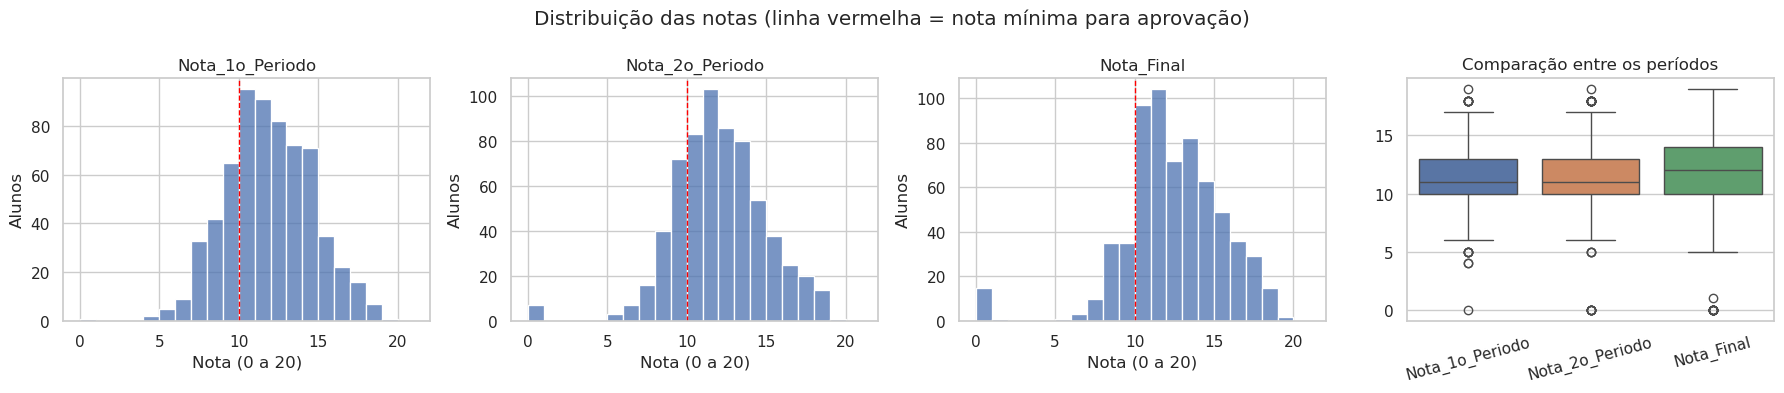

,count,mean,std,min,25%,50%,75%,max
Nota_1o_Periodo,649.0,11.40,2.75,0.0,10.0,11.0,13.0,19.0
Nota_2o_Periodo,649.0,11.57,2.91,0.0,10.0,11.0,13.0,19.0
Nota_Final,649.0,11.91,3.23,0.0,10.0,12.0,14.0,19.0


In [14]:
colunas_notas = ["Nota_1o_Periodo", "Nota_2o_Periodo", "Nota_Final"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, coluna in enumerate(colunas_notas):
    sns.histplot(df[coluna], bins=21, binrange=(0, 21), ax=axes[i])
    axes[i].axvline(10, color="red", linestyle="--", linewidth=1)
    axes[i].set_title(coluna)
    axes[i].set_xlabel("Nota (0 a 20)")
    axes[i].set_ylabel("Alunos")

sns.boxplot(data=df[colunas_notas], ax=axes[3])
axes[3].set_title("Comparação entre os períodos")
axes[3].tick_params(axis="x", rotation=15)

plt.suptitle("Distribuição das notas (linha vermelha = nota mínima para aprovação)")
plt.tight_layout()
plt.show()

df[colunas_notas].describe().T.round(2)

As notas se concentram entre 10 e 14 nos três períodos (mediana 11 no 1º e no 2º, 12 na final). O que chama atenção é a cauda à esquerda: há alunos com nota zero no 2º período (7) e, principalmente, na nota final (15), separados do restante da distribuição. Investigamos esses casos abaixo.

In [15]:
print("Alunos com nota 0 em cada período:")
print((df[colunas_notas] == 0).sum())

nota_zero = df[df["Nota_Final"] == 0]
print("\nAlunos com nota final 0:", len(nota_zero), f"({len(nota_zero) / len(df) * 100:.2f}% da base)")
print("Escola desses alunos:", nota_zero["Escola"].value_counts().to_dict())
print("Faltas desses alunos:", nota_zero["Numero_de_Faltas"].value_counts().to_dict())

nota_zero[["Escola", "Idade", "Numero_de_Faltas", "Nota_1o_Periodo", "Nota_2o_Periodo", "Nota_Final"]]

Alunos com nota 0 em cada período:
Nota_1o_Periodo     1
Nota_2o_Periodo     7
Nota_Final         15
dtype: int64

Alunos com nota final 0: 15 (2.31% da base)
Escola desses alunos: {'MS': 14, 'GP': 1}
Faltas desses alunos: {0: 15}


,Escola,Idade,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
163,GP,18,0,11,9,0
440,MS,16,0,7,0,0
519,MS,16,0,8,7,0
563,MS,17,0,7,0,0
567,MS,18,0,4,0,0
583,MS,18,0,8,6,0
586,MS,17,0,8,8,0
597,MS,18,0,9,0,0
603,MS,18,0,5,0,0
605,MS,19,0,5,0,0


São 15 alunos com nota final zero (2,31%). Todos têm zero faltas e 14 deles são da escola MS. No 1º período eles tiveram notas entre 4 e 11, ou seja, ainda estavam sendo avaliados, e 7 deles já ficaram com zero no 2º período (são os mesmos 7 alunos com zero no 2º período da base toda). Isso indica que esses alunos deixaram de ser avaliados ao longo do ano, provavelmente porque abandonaram a escola ou não fizeram as avaliações (a base não diz qual dos dois). O zero de faltas também sugere que a contagem parou quando o aluno saiu.

Decisão: mantivemos esses alunos. Para a escola, um aluno que abandona é exatamente o caso que ela quer identificar, e retirar esses registros deixaria o modelo otimista demais. Esses alunos entram no alvo como reprovados.

## 2.12 Faltas e valores atípicos

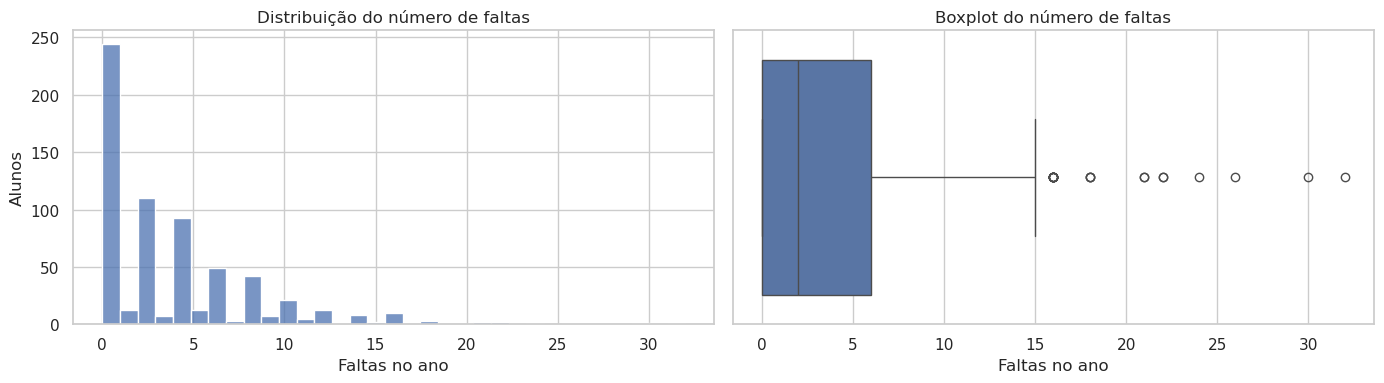

Q1 = 0 | Q3 = 6 | limite superior pelo IQR = 15 faltas
Alunos acima do limite: 21
Nota final média desses alunos: 10.76 (base toda: 11.91)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df["Numero_de_Faltas"], bins=33, ax=axes[0])
axes[0].set_title("Distribuição do número de faltas")
axes[0].set_xlabel("Faltas no ano")
axes[0].set_ylabel("Alunos")

sns.boxplot(x=df["Numero_de_Faltas"], ax=axes[1])
axes[1].set_title("Boxplot do número de faltas")
axes[1].set_xlabel("Faltas no ano")

plt.tight_layout()
plt.show()

# limite de valores atípicos pelo IQR
q1 = df["Numero_de_Faltas"].quantile(0.25)
q3 = df["Numero_de_Faltas"].quantile(0.75)
limite_superior = q3 + 1.5 * (q3 - q1)
atipicos = df[df["Numero_de_Faltas"] > limite_superior]

print(f"Q1 = {q1:.0f} | Q3 = {q3:.0f} | limite superior pelo IQR = {limite_superior:.0f} faltas")
print("Alunos acima do limite:", len(atipicos))
print(f"Nota final média desses alunos: {atipicos['Nota_Final'].mean():.2f} (base toda: {df['Nota_Final'].mean():.2f})")

A distribuição das faltas é bem assimétrica: metade dos alunos tem até 2 faltas e 75% tem até 6, mas o máximo chega a 32. Pelo critério do IQR, 21 alunos têm mais de 15 faltas. Esses valores são possíveis no contexto escolar (estão bem abaixo do máximo de 93 da documentação), então não removemos nem cortamos esses registros. Como as faltas registradas são o total do ano inteiro, elas não entram no modelo (ver Etapa 3) e aparecem só nesta análise exploratória.

## 2.13 Tempo de estudo e reprovações anteriores

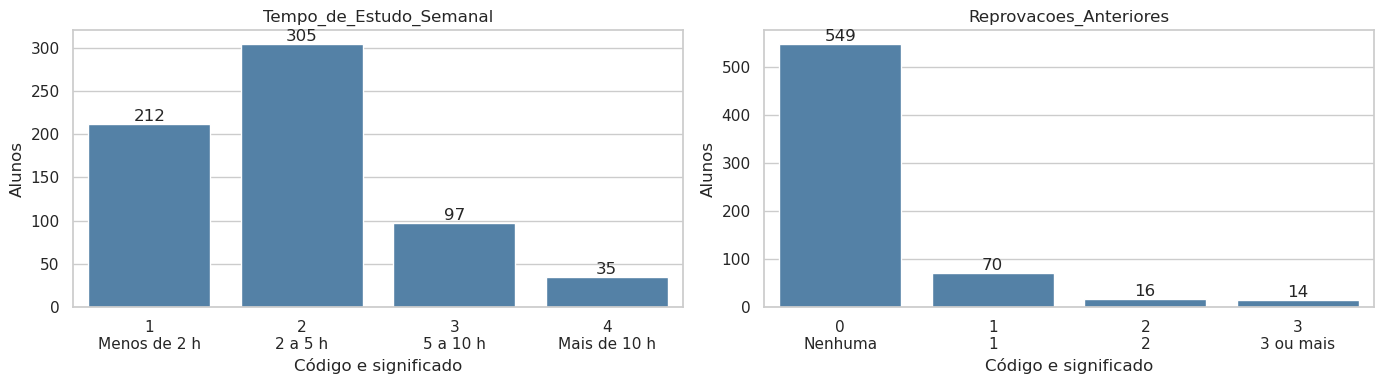

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for i, coluna in enumerate(["Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores"]):
    ordem = sorted(df[coluna].unique())
    sns.countplot(x=df[coluna], order=ordem, ax=axes[i], color="steelblue")
    # troca o código pelo significado no eixo
    rotulos = [f"{c}\n{dicionario_codigos[coluna][c]}" for c in ordem]
    axes[i].set_xticks(range(len(ordem)))
    axes[i].set_xticklabels(rotulos)
    axes[i].set_title(coluna)
    axes[i].set_xlabel("Código e significado")
    axes[i].set_ylabel("Alunos")
    axes[i].bar_label(axes[i].containers[0])

plt.tight_layout()
plt.show()

517 dos 649 alunos (cerca de 80%) estudam menos de 5 horas por semana (códigos 1 e 2), e só 35 estudam mais de 10 horas. Quanto às reprovações, 549 alunos (84,6%) nunca reprovaram e 100 têm de 1 a 3 reprovações no histórico.

## 2.14 Relações com a nota final

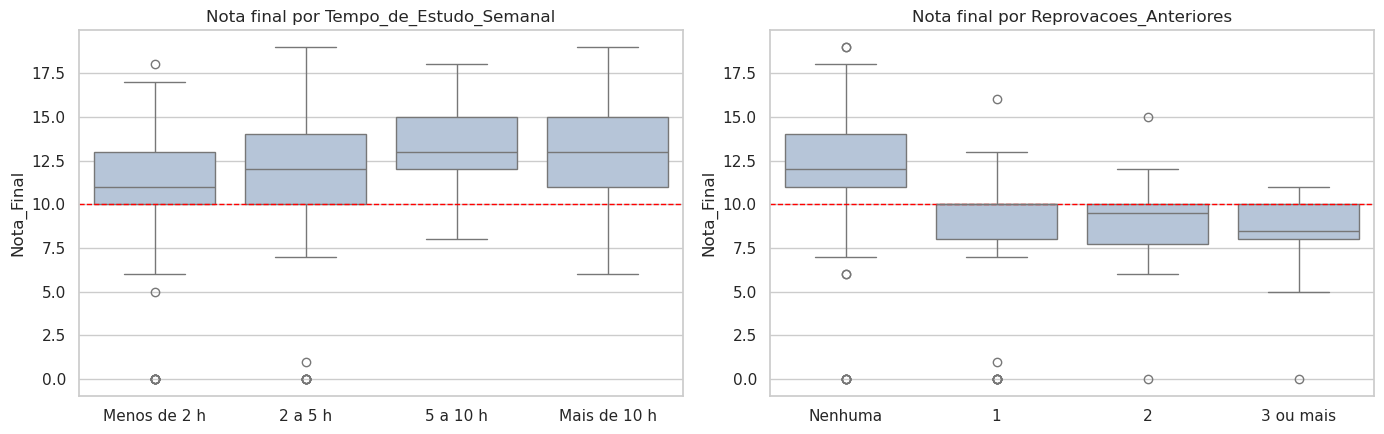

Tempo_de_Estudo_Semanal


,Alunos,Média da nota final,Mediana
1 - Menos de 2 h,212,10.84,11.0
2 - 2 a 5 h,305,12.09,12.0
3 - 5 a 10 h,97,13.23,13.0
4 - Mais de 10 h,35,13.06,13.0


Reprovacoes_Anteriores


,Alunos,Média da nota final,Mediana
0 - Nenhuma,549,12.51,12.0
1 - 1,70,8.64,10.0
2 - 2,16,8.81,9.5
3 - 3 ou mais,14,8.07,8.5


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for i, coluna in enumerate(["Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores"]):
    ordem = sorted(df[coluna].unique())
    sns.boxplot(x=df[coluna], y=df["Nota_Final"], order=ordem, ax=axes[i], color="lightsteelblue")
    axes[i].set_xticks(range(len(ordem)))
    axes[i].set_xticklabels([dicionario_codigos[coluna][c] for c in ordem])
    axes[i].axhline(10, color="red", linestyle="--", linewidth=1)
    axes[i].set_title("Nota final por " + coluna)
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

for coluna in ["Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores"]:
    resumo = df.groupby(coluna)["Nota_Final"].agg(["count", "mean", "median"]).round(2)
    resumo.columns = ["Alunos", "Média da nota final", "Mediana"]
    resumo.index = [f"{c} - {dicionario_codigos[coluna][c]}" for c in resumo.index]
    print(coluna)
    display(resumo)

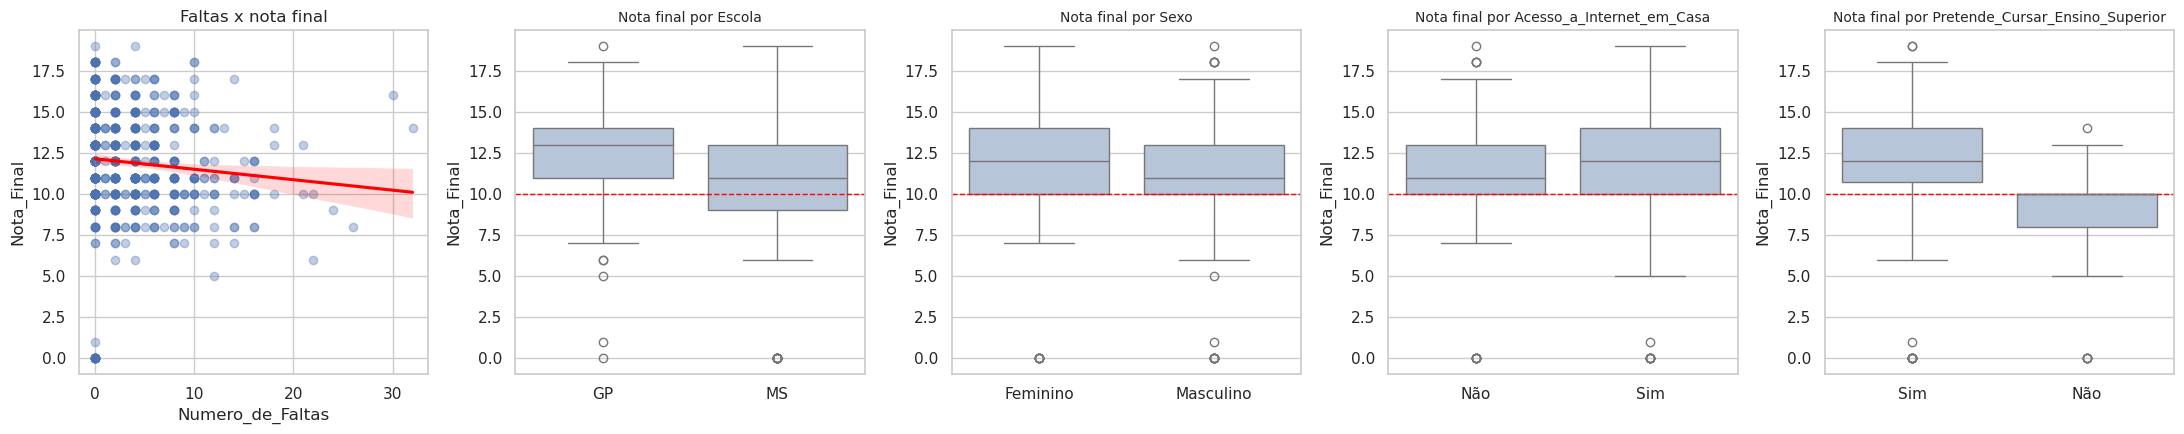

Escola {'GP': 12.58, 'MS': 10.65}
Sexo {'Feminino': 12.25, 'Masculino': 11.41}
Acesso_a_Internet_em_Casa {'Não': 11.03, 'Sim': 12.17}
Pretende_Cursar_Ensino_Superior {'Não': 8.8, 'Sim': 12.28}


In [19]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))

sns.regplot(data=df, x="Numero_de_Faltas", y="Nota_Final", ax=axes[0],
            scatter_kws={"alpha": 0.35}, line_kws={"color": "red"})
axes[0].set_title("Faltas x nota final")

colunas = ["Escola", "Sexo", "Acesso_a_Internet_em_Casa", "Pretende_Cursar_Ensino_Superior"]
for i, coluna in enumerate(colunas):
    sns.boxplot(data=df, x=coluna, y="Nota_Final", ax=axes[i + 1], color="lightsteelblue")
    axes[i + 1].axhline(10, color="red", linestyle="--", linewidth=1)
    axes[i + 1].set_title("Nota final por " + coluna, fontsize=10)
    axes[i + 1].set_xlabel("")

plt.tight_layout()
plt.show()

# média da nota final em cada grupo
for coluna in colunas:
    print(coluna, df.groupby(coluna)["Nota_Final"].mean().round(2).to_dict())

A nota final sobe com o tempo de estudo: a média vai de 10,84 para quem estuda menos de 2 h por semana até 13,23 para quem estuda de 5 a 10 h (o grupo de mais de 10 h, com só 35 alunos, fica em 13,06). O efeito das reprovações anteriores é ainda maior: quem nunca reprovou tem média 12,51, e quem já reprovou fica entre 8,07 e 8,81, abaixo da nota mínima para aprovação.

As faltas têm relação negativa com a nota, mas fraca: a reta cai pouco e os pontos estão muito espalhados. Entre as variáveis de texto, as maiores diferenças estão em querer cursar o ensino superior (média 12,28 contra 8,80) e na escola (GP 12,58 contra MS 10,65). Sexo e acesso à internet mostram diferenças menores, de cerca de 1 ponto.

## 2.15 Correlação

Usamos a correlação de Spearman, que trabalha com a ordem dos valores. Ela é mais adequada que a de Pearson aqui, porque boa parte das variáveis são escalas ordinais (1 a 5, 0 a 4) e não medidas contínuas.

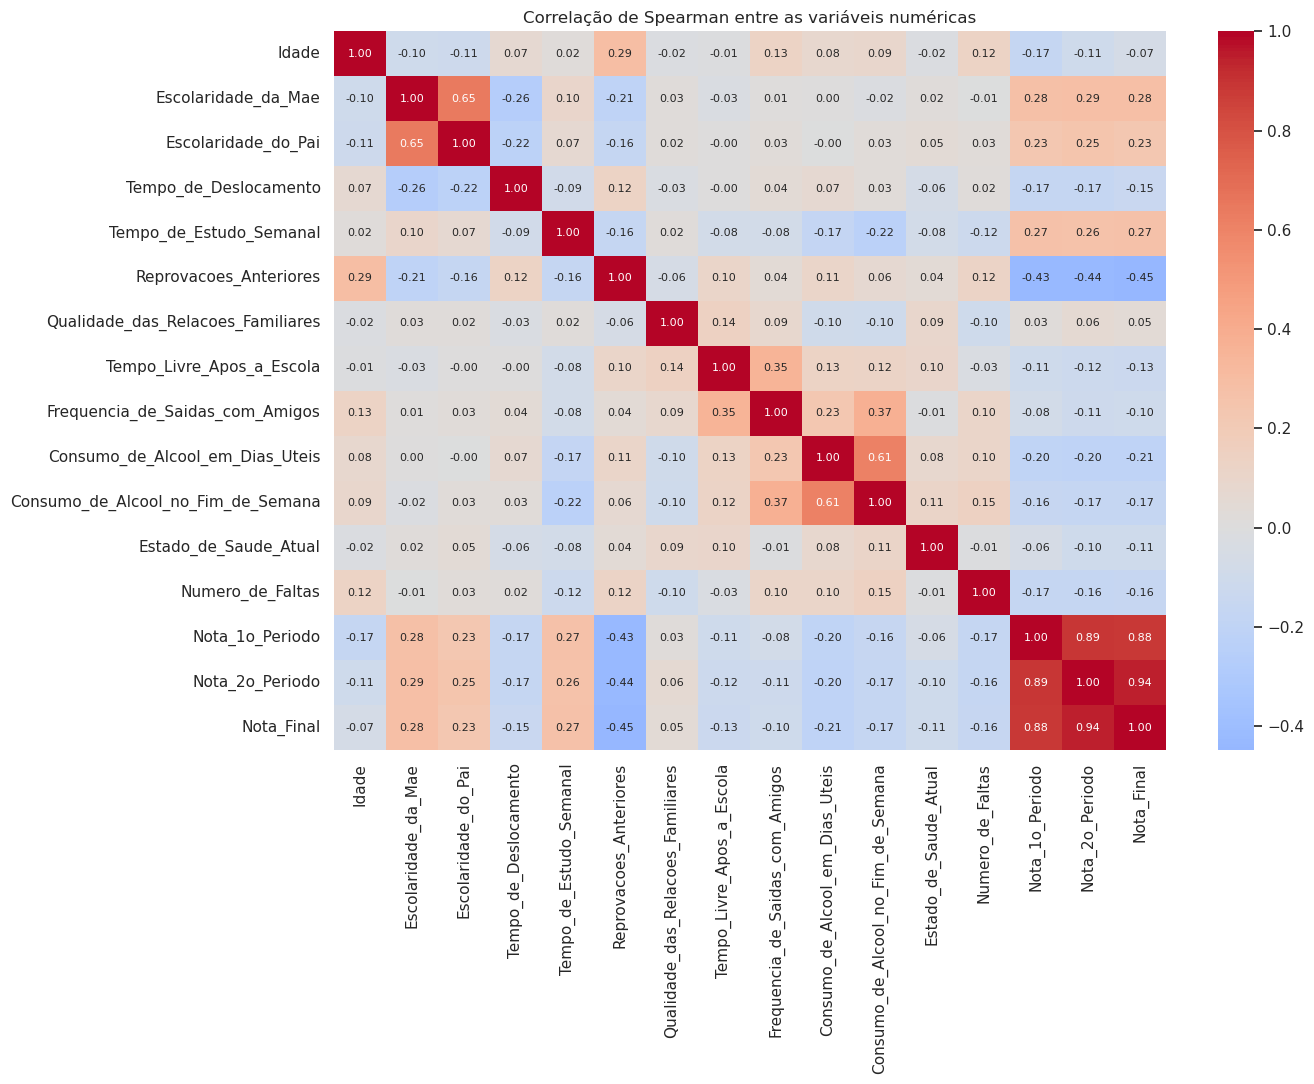

Reprovacoes_Anteriores               -0.448
Consumo_de_Alcool_em_Dias_Uteis      -0.208
Consumo_de_Alcool_no_Fim_de_Semana   -0.171
Numero_de_Faltas                     -0.159
Tempo_de_Deslocamento                -0.147
Tempo_Livre_Apos_a_Escola            -0.128
Estado_de_Saude_Atual                -0.106
Frequencia_de_Saidas_com_Amigos      -0.105
Idade                                -0.066
Qualidade_das_Relacoes_Familiares     0.048
Escolaridade_do_Pai                   0.235
Tempo_de_Estudo_Semanal               0.275
Escolaridade_da_Mae                   0.284
Nota_1o_Periodo                       0.883
Nota_2o_Periodo                       0.944
Name: Nota_Final, dtype: float64

In [20]:
# Spearman, porque muitas variáveis são escalas com ordem (1 a 5, 0 a 4)
correlacao = df[colunas_numericas].corr(method="spearman")

plt.figure(figsize=(14, 11))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlação de Spearman entre as variáveis numéricas")
plt.tight_layout()
plt.show()

# correlação de cada variável com a nota final
correlacao["Nota_Final"].drop("Nota_Final").sort_values().round(3)

Com a nota final, as correlações mais fortes são as notas do 2º período (0,944) e do 1º período (0,883). Fora as notas, o destaque é `Reprovacoes_Anteriores` (-0,448), seguida de escolaridade da mãe (0,284), tempo de estudo (0,275), escolaridade do pai (0,235) e consumo de álcool em dias úteis (-0,208). No mapa de calor esses valores aparecem com duas casas decimais. As demais ficam abaixo de 0,2 em módulo, ou seja, sozinhas dizem pouco sobre a nota.

Isso tem consequências para a modelagem:

* As notas parciais são quase a própria resposta. Usá-las num modelo que deveria funcionar no início do ano seria vazamento de informação, e por isso criamos os cenários A e B (Etapa 3).
* Sem as notas, nenhuma variável isolada explica muito, então já esperamos um desempenho bem mais modesto no Cenário A.
* Algumas entradas são correlacionadas entre si: escolaridade da mãe e do pai (0,65) e os dois tipos de consumo de álcool (0,61). Isso pode deixar os coeficientes da Regressão Logística instáveis, um motivo a mais para usar regularização.

## 2.16 Situação final e desbalanceamento das classes

Criamos `Situacao_Final` (Aprovado se nota final >= 10, Reprovado se < 10) apenas para a análise exploratória.

Situacao_Final
Aprovado     549
Reprovado    100
Name: count, dtype: int64
Situacao_Final
Aprovado     84.59
Reprovado    15.41
Name: count, dtype: float64


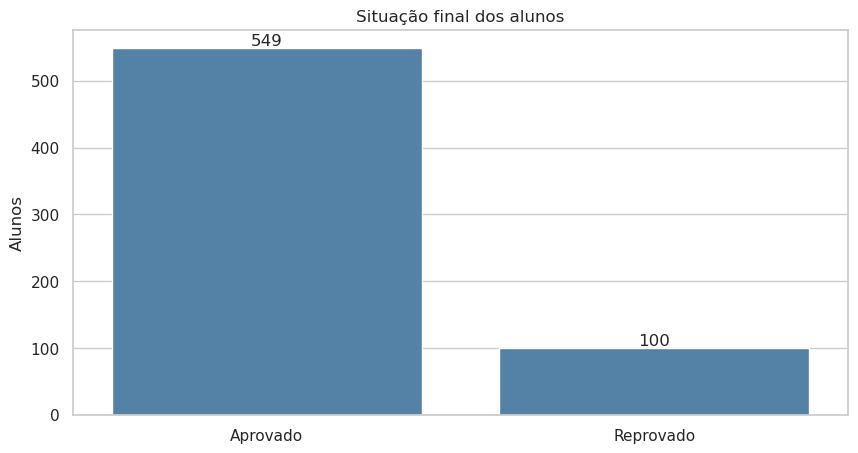

In [21]:
df["Situacao_Final"] = np.where(df["Nota_Final"] >= 10, "Aprovado", "Reprovado")

contagem = df["Situacao_Final"].value_counts()
print(contagem)
print((contagem / len(df) * 100).round(2))

ax = sns.countplot(data=df, x="Situacao_Final", order=["Aprovado", "Reprovado"], color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Situação final dos alunos")
plt.xlabel("")
plt.ylabel("Alunos")
plt.show()

In [22]:
# % de aprovados e reprovados em cada grupo
for coluna in ["Reprovacoes_Anteriores", "Tempo_de_Estudo_Semanal", "Escola", "Acesso_a_Internet_em_Casa"]:
    taxa = pd.crosstab(df[coluna], df["Situacao_Final"], normalize="index") * 100
    if coluna in dicionario_codigos:
        taxa.index = [f"{c} - {dicionario_codigos[coluna][c]}" for c in taxa.index]
    print(coluna)
    display(taxa.round(2))

# a mesma conta por escola, tirando os alunos com nota final 0
sem_zero = df[df["Nota_Final"] > 0]
print("Por escola, sem os alunos com nota final 0:")
(pd.crosstab(sem_zero["Escola"], sem_zero["Situacao_Final"], normalize="index") * 100).round(2)

Reprovacoes_Anteriores


Situacao_Final,Aprovado,Reprovado
0 - Nenhuma,90.71,9.29
1 - 1,54.29,45.71
2 - 2,50.00,50.00
3 - 3 ou mais,35.71,64.29


Tempo_de_Estudo_Semanal


Situacao_Final,Aprovado,Reprovado
1 - Menos de 2 h,76.42,23.58
2 - 2 a 5 h,86.56,13.44
3 - 5 a 10 h,92.78,7.22
4 - Mais de 10 h,94.29,5.71


Escola


Situacao_Final,Aprovado,Reprovado
Escola,,
GP,92.43,7.57
MS,69.91,30.09


Acesso_a_Internet_em_Casa


Situacao_Final,Aprovado,Reprovado
Acesso_a_Internet_em_Casa,,
Não,78.81,21.19
Sim,86.35,13.65


Por escola, sem os alunos com nota final 0:


Situacao_Final,Aprovado,Reprovado
Escola,,
GP,92.65,7.35
MS,74.53,25.47


São 549 aprovados (84,59%) e 100 reprovados (15,41%), ou seja, as classes são desbalanceadas. A taxa de reprovação muda bastante entre os grupos:

* 9,29% entre quem nunca reprovou, contra 45,71% a 64,29% entre quem já reprovou;
* 23,58% entre quem estuda menos de 2 h por semana, contra 7,22% e 5,71% nos dois níveis de mais estudo;
* 30,09% na escola MS, contra 7,57% na GP. Dos 15 alunos com nota final zero, 14 são da MS, mas mesmo retirando esses alunos a diferença continua grande (25,47% contra 7,35%);
* 21,19% entre quem não tem internet em casa, contra 13,65% entre quem tem.

O desbalanceamento define duas escolhas da classificação: não vamos julgar os modelos pela acurácia (dizer "aprovado" para todo mundo já dá 84,6%) e vamos testar `class_weight="balanced"`, para que o modelo dê mais peso aos reprovados.

## 2.17 Decisões de codificação e padronização

Com base no que vimos, definimos como cada tipo de variável será transformado. Nada é ajustado aqui: os transformadores são montados num `ColumnTransformer` e aprendem médias, desvios e categorias apenas com os dados de treino, na Etapa 4.

| Tipo de variável | Exemplos | Transformação | Motivo |
|---|---|---|---|
| Binárias de texto | `Sexo`, `Escola`, sim/não | `OneHotEncoder(drop="if_binary")`, vira uma coluna 0/1 | Os modelos só trabalham com números; com duas categorias basta uma coluna |
| Nominais com mais de 2 categorias | `Ocupacao_da_Mae`, `Motivo_da_Escolha_da_Escola` | `OneHotEncoder`, uma coluna 0/1 por categoria | Não existe ordem entre "Saúde" e "Serviços"; transformar em 1, 2, 3 criaria uma ordem falsa |
| Ordinais (códigos) | `Escolaridade_da_Mae`, `Tempo_de_Estudo_Semanal` | Mantidas como número e padronizadas | A ordem tem significado (código 3 estuda mais que código 1) |
| Contínuas / contagens | `Idade` e notas parciais | `StandardScaler` (média 0, desvio 1) | As escalas são muito diferentes (idade de 15 a 22, notas de 0 a 20, escalas de 1 a 5); isso afeta a regularização da Regressão Logística |
| Valores ausentes | nenhuma coluna | sem imputação | A base não tem ausentes (seção 2.6) |

Não aplicamos transformação logarítmica nas faltas, porque elas não entram no modelo.

In [23]:
binarias = [c for c in colunas_categoricas if df[c].nunique() == 2]
nominais = [c for c in colunas_categoricas if df[c].nunique() > 2]
ordinais = list(dicionario_codigos.keys())
continuas = [c for c in colunas_numericas if c not in ordinais]

print("Binárias:", binarias)
print("Nominais:", nominais)
print("Ordinais (códigos):", ordinais)
print("Contínuas / contagens:", continuas)

Binárias: ['Escola', 'Sexo', 'Tipo_de_Endereco', 'Tamanho_da_Familia', 'Situacao_dos_Pais', 'Apoio_Educacional_da_Escola', 'Apoio_Educacional_Familiar', 'Aulas_Particulares_Pagas', 'Atividades_Extracurriculares', 'Frequentou_Educacao_Infantil', 'Pretende_Cursar_Ensino_Superior', 'Acesso_a_Internet_em_Casa', 'Relacionamento_Amoroso']
Nominais: ['Ocupacao_da_Mae', 'Ocupacao_do_Pai', 'Motivo_da_Escolha_da_Escola', 'Responsavel']
Ordinais (códigos): ['Escolaridade_da_Mae', 'Escolaridade_do_Pai', 'Tempo_de_Deslocamento', 'Tempo_de_Estudo_Semanal', 'Reprovacoes_Anteriores', 'Qualidade_das_Relacoes_Familiares', 'Tempo_Livre_Apos_a_Escola', 'Frequencia_de_Saidas_com_Amigos', 'Consumo_de_Alcool_em_Dias_Uteis', 'Consumo_de_Alcool_no_Fim_de_Semana', 'Estado_de_Saude_Atual']
Contínuas / contagens: ['Idade', 'Numero_de_Faltas', 'Nota_1o_Periodo', 'Nota_2o_Periodo', 'Nota_Final']


## 2.18 Resumo da qualidade da base

In [24]:
reprovados = (df["Situacao_Final"] == "Reprovado").mean() * 100

print("Estudantes:", len(df))
print("Variáveis originais: 33")
print("Valores ausentes:", df.isnull().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
print("Valores fora da escala:", total_fora)
print("Alunos com nota final 0:", (df["Nota_Final"] == 0).sum())
print("Alunos com mais de 15 faltas:", len(atipicos))
print(f"% de reprovados: {reprovados:.2f}%")

Estudantes: 649
Variáveis originais: 33
Valores ausentes: 0
Linhas duplicadas: 0
Valores fora da escala: 0
Alunos com nota final 0: 15
Alunos com mais de 15 faltas: 21
% de reprovados: 15.41%


### Conclusão da Etapa 2: como a EDA orienta a modelagem

1. Ausentes e duplicados: não existem, então não há imputação nem exclusão de linhas.
2. Notas zero e faltas altas: são casos reais (prováveis abandonos e alunos muito faltosos) e foram mantidos. Os alunos com nota zero entram no alvo como reprovados.
3. Escala e codificação: as variáveis têm escalas muito diferentes e há 17 colunas de texto. Usaremos `StandardScaler` e `OneHotEncoder` dentro de um `Pipeline`, ajustados só no treino.
4. Vazamento temporal: as notas parciais têm correlação de 0,88 e 0,94 com a nota final. Por isso a modelagem é feita em dois cenários: A, sem as notas parciais, e B, com elas. As faltas são o total do ano inteiro e ficam fora dos modelos.
5. Desbalanceamento: 15,41% de reprovados. Na classificação usaremos divisão estratificada, `class_weight="balanced"` e métricas focadas na classe reprovado (recall, precisão e F1).

---

# Etapa 3: Definição da Tarefa

> **Enunciado da Especificação (Etapa 3):** *"3. Definição da tarefa: supervisionada ou não supervisionada; se supervisionada, regressão ou classificação."*

| Tarefa | Tipo | Alvo | Métricas |
|---|---|---|---|
| Prever se o aluno vai reprovar | Supervisionada - classificação binária | `Risco_Reprovacao` (1 = reprovado, 0 = aprovado) | Recall, precisão e F1 da classe reprovado, e matriz de confusão |

É uma tarefa supervisionada, porque a base traz a resposta (a nota final) de cada aluno, e de classificação, porque o alvo tem duas classes.

Sobre as métricas, considerando os reprovados como a classe de interesse:

* Recall: dos alunos que reprovaram, quantos o modelo encontrou. É a métrica que mais importa para a escola, porque cada reprovado não encontrado é um aluno que deixa de receber ajuda.
* Precisão: dos alunos que o modelo indicou, quantos de fato reprovaram. Também conta bastante, já que as vagas de reforço são limitadas e cada falso alarme ocupa uma vaga que poderia ir para quem precisa.
* F1: média harmônica entre precisão e recall. Foi a métrica usada para escolher o modelo, porque só fica alta quando as duas são boas ao mesmo tempo. Olhando só o recall, bastaria indicar todos os alunos; olhando só a precisão, bastaria indicar quase ninguém.
* Matriz de confusão: mostra acertos e erros em número de alunos, o que facilita explicar o resultado para a escola ("encontramos 14 de 20 reprovados, com 19 falsos alarmes").
* Acurácia: aparece só para comparação, e não serve para decidir. Com 15% de reprovados, um modelo que diz "aprovado" para todos já acerta 85%, sem encontrar nenhum reprovado.

### 3.1 Variáveis disponíveis em cada cenário

Uma variável só pode entrar no modelo se estiver disponível no momento em que a previsão é feita:

* `Nota_Final`, `Situacao_Final` e `Risco_Reprovacao` são a própria resposta e nunca entram como entrada.
* `Nota_1o_Periodo` e `Nota_2o_Periodo` só existem depois desses períodos, então ficam fora do Cenário A e entram no Cenário B.
* `Numero_de_Faltas` é o total de faltas do ano inteiro, vindo do boletim. No início do ano esse número ainda não existe, e no fim do 2º período ele ainda não está completo, porque inclui faltas do 3º período. A base não traz as faltas acumuladas até o 2º período, então deixamos essa variável fora dos dois cenários. Ela aparece só na análise exploratória.

In [25]:
# alvo: 1 = reprovado (nota final menor que 10), 0 = aprovado
df["Risco_Reprovacao"] = (df["Nota_Final"] < 10).astype(int)

respostas = ["Nota_Final", "Situacao_Final", "Risco_Reprovacao"]  # são a própria resposta
notas_parciais = ["Nota_1o_Periodo", "Nota_2o_Periodo"]          # só existem depois dos períodos

# Cenário A (início do ano): sem notas parciais e sem faltas (total do ano)
features_a = [c for c in df.columns if c not in respostas + notas_parciais + ["Numero_de_Faltas"]]

# Cenário B (fim do 2º período): entram também as notas parciais
features_b = features_a + notas_parciais

print("Cenário A:", len(features_a), "variáveis")
print("Cenário B:", len(features_b), "variáveis")

Cenário A: 29 variáveis
Cenário B: 31 variáveis


### 3.2 Divisão treino e teste (antes de qualquer ajuste)

Separamos 80% dos alunos para treino e 20% para teste, com estratificação pelo `Risco_Reprovacao` para manter a mesma proporção de reprovados nos dois conjuntos. Assim, o treino fica com 519 alunos (80 reprovados) e o teste com 130 (20 reprovados), somando os 649 alunos e 100 reprovados da base. Sempre que o notebook fala em 519 alunos, está se referindo ao treino; quando fala em 130, ao teste. O conjunto de teste fica guardado e só é usado uma vez, na Etapa 5.

A proporção 80/20 deixa a maior parte dos dados para o treino, que ainda será dividido de novo na validação cruzada. Os 20% do teste (130 alunos, 20 reprovados) são o mínimo razoável para avaliar o modelo em alunos que ele nunca viu.

A estratificação foi necessária porque, com só 100 reprovados na base, uma divisão ao acaso poderia deixar o teste com bem mais ou bem menos reprovados que o treino, e os resultados ficariam distorcidos. Com a estratificação, os dois conjuntos ficam com a mesma proporção.

In [26]:
treino, teste = train_test_split(df, test_size=0.2, random_state=SEMENTE, stratify=df["Risco_Reprovacao"])

y_treino = treino["Risco_Reprovacao"]
y_teste = teste["Risco_Reprovacao"]

print(f"Treino: {len(treino)} alunos, {y_treino.sum()} reprovados ({y_treino.mean() * 100:.2f}%)")
print(f"Teste: {len(teste)} alunos, {y_teste.sum()} reprovados ({y_teste.mean() * 100:.2f}%)")

Treino: 519 alunos, 80 reprovados (15.41%)
Teste: 130 alunos, 20 reprovados (15.38%)


---

# Etapa 4: Construção do Modelo

> **Enunciado da Especificação (Etapa 4):** *"4. Construção do modelo: algoritmos adequados ao problema, sempre comparados com uma referência simples (por exemplo, prever a média ou a classe mais comum)."*

Todos os modelos são montados como `Pipeline(pré-processamento + modelo)`. Assim, o `StandardScaler` e o `OneHotEncoder` são ajustados de novo em cada rodada, só com os dados de treino daquela rodada.

Para escolher hiperparâmetros (força da regularização, profundidade das árvores) e comparar os modelos, usamos validação cruzada com 5 partes dentro do conjunto de treino (`GridSearchCV`). O teste não participa de nenhuma escolha.

Preferimos a validação cruzada a separar mais um pedaço fixo do treino para validar, porque isso deixaria poucos reprovados para treinar (o treino tem só 80). Na validação cruzada, o treino é dividido em 5 partes; o modelo é treinado em 4 e avaliado na quinta, 5 vezes, e o resultado é a média das 5 rodadas. Assim todos os alunos do treino são usados, e o resultado é mais estável do que o de uma única divisão. As partes também são estratificadas, pelo mesmo motivo da divisão treino/teste.

O `Pipeline` garante que a padronização e a codificação aprendam só com a parte de treino de cada rodada. Sem ele, a média e o desvio usados na padronização incluiriam alunos da validação, o que é uma forma de vazamento.

Usamos dois tipos de referência simples:

* Referência ingênua (`DummyClassifier`): prevê sempre a classe mais comum (aprovado). Mostra o mínimo que qualquer modelo precisa superar.
* Referência por regra, que é o que a escola faria sem Machine Learning. No Cenário A, a regra é "quem já reprovou antes está em risco". No Cenário B, é "quem tirou menos de 10 no 2º período está em risco". Essas regras não aprendem nada dos dados, então não há risco de vazamento. Se um modelo não supera a regra, ele não justifica a complexidade.

In [27]:
def criar_pipeline(modelo, features):
    numericas = [c for c in features if c in colunas_numericas]
    categoricas = [c for c in features if c in colunas_categoricas]
    preprocessamento = ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categoricas),
    ])
    return Pipeline([("prep", preprocessamento), ("modelo", modelo)])


# regras simples: o que a escola faria sem Machine Learning
def regra_a(dados):
    # Cenário A: quem já reprovou antes está em risco
    return (dados["Reprovacoes_Anteriores"] > 0).astype(int)

def regra_b(dados):
    # Cenário B: quem tirou menos de 10 no 2º período está em risco
    return (dados["Nota_2o_Periodo"] < 10).astype(int)

## 4.1 Modelos de classificação - `Risco_Reprovacao`

* Referências: `DummyClassifier`, que prevê sempre a classe mais comum (aprovado), e as regras "já reprovou antes" (Cenário A) e "nota do 2º período < 10" (Cenário B), descritas acima. Um modelo só vale a pena se for melhor que as duas.
* Regressão Logística sem balanceamento: é o modelo de classificação mais simples visto na disciplina, e mantê-lo sem balanceamento mostra o que acontece quando o desbalanceamento é ignorado.
* Regressão Logística balanceada: `class_weight="balanced"` dá mais peso aos reprovados, e a força da regularização L2 (`C`) é escolhida na validação. Além de tratar o desbalanceamento, ela tem outra vantagem: os coeficientes mostram se cada variável aumenta ou reduz o risco, o que ajuda a explicar o resultado para a escola.
* Random Forest balanceado: conjunto de árvores de decisão, também com `class_weight="balanced"`, com profundidade e tamanho das folhas escolhidos na validação. Entrou porque as árvores conseguem combinar variáveis (por exemplo, escola e reprovações anteriores ao mesmo tempo) e captar relações que não são lineares, o que a Logística não faz sozinha. Limitar a profundidade evita que as árvores decorem o treino.

Na validação cruzada usamos partes estratificadas e escolhemos os hiperparâmetros pelo F1 da classe reprovado, que equilibra encontrar reprovados (recall) e não gerar alarmes demais (precisão).

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

# zero_division=0 evita aviso quando o modelo não aponta nenhum reprovado (caso do Dummy)
metricas = {
    "f1": make_scorer(f1_score, zero_division=0),
    "recall": "recall",
    "precisao": make_scorer(precision_score, zero_division=0),
}


def avaliar_regra_cv(nome, regra, X, y):
    # a regra não aprende nada: só calculamos as métricas em cada parte da validação
    f1_treino, f1_val, recall_val, precisao_val = [], [], [], []
    for i_treino, i_val in cv.split(X, y):
        f1_treino.append(f1_score(y.iloc[i_treino], regra(X.iloc[i_treino])))
        previsto = regra(X.iloc[i_val])
        f1_val.append(f1_score(y.iloc[i_val], previsto))
        recall_val.append(recall_score(y.iloc[i_val], previsto))
        precisao_val.append(precision_score(y.iloc[i_val], previsto, zero_division=0))
    return {"Modelo": nome, "Hiperparâmetros escolhidos": "-",
            "Recall validação (CV)": np.mean(recall_val), "Precisão validação (CV)": np.mean(precisao_val),
            "F1 treino (CV)": np.mean(f1_treino), "F1 validação (CV)": np.mean(f1_val),
            "F1 em cada parte (CV)": np.round(f1_val, 2)}


def treinar_modelos(features, regra, nome_regra):
    X = treino[features]
    modelos = {
        "Referência (classe mais comum)": (DummyClassifier(strategy="most_frequent"), {}),
        "Logística sem balanceamento": (LogisticRegression(max_iter=2000), {}),
        "Logística balanceada (L2)": (LogisticRegression(class_weight="balanced", max_iter=2000),
                                      {"modelo__C": [0.0001, 0.001, 0.003, 0.01, 0.05, 0.1, 0.5, 1, 10]}),
        "Random Forest balanceado": (RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                            random_state=SEMENTE, n_jobs=-1),
                                     {"modelo__max_depth": [1, 2, 3, 5, 8, 12, None],
                                      "modelo__min_samples_leaf": [1, 5, 10]}),
    }

    resultados = []
    treinados = {}
    for nome, (modelo, parametros) in modelos.items():
        busca = GridSearchCV(criar_pipeline(modelo, features), parametros, cv=cv,
                             scoring=metricas, refit="f1", return_train_score=True)
        busca.fit(X, y_treino)
        r = busca.cv_results_
        i = busca.best_index_
        resultados.append({
            "Modelo": nome,
            "Hiperparâmetros escolhidos": str(busca.best_params_).replace("modelo__", "") if parametros else "-",
            "Recall validação (CV)": r["mean_test_recall"][i],
            "Precisão validação (CV)": r["mean_test_precisao"][i],
            "F1 treino (CV)": r["mean_train_f1"][i],
            "F1 validação (CV)": r["mean_test_f1"][i],
            "F1 em cada parte (CV)": np.round([r[f"split{k}_test_f1"][i] for k in range(5)], 2),
        })
        treinados[nome] = busca.best_estimator_

    # a regra entra logo depois do Dummy, junto com as referências
    resultados.insert(1, avaliar_regra_cv(nome_regra, regra, X, y_treino))
    return pd.DataFrame(resultados).round(3), treinados


cv_a, modelos_a = treinar_modelos(features_a, regra_a, "Referência (regra: já reprovou antes)")
cv_b, modelos_b = treinar_modelos(features_b, regra_b, "Referência (regra: nota do 2º período < 10)")

print("Cenário A - início do ano (validação cruzada no treino)")
display(cv_a)
print("Cenário B - com notas do 1º e 2º períodos (validação cruzada no treino)")
display(cv_b)

# escolhido = modelo com maior F1 na validação (as referências não contam)
candidatos_a = cv_a[~cv_a["Modelo"].str.startswith("Referência")]
candidatos_b = cv_b[~cv_b["Modelo"].str.startswith("Referência")]
escolhido_a = candidatos_a.sort_values("F1 validação (CV)", ascending=False)["Modelo"].iloc[0]
escolhido_b = candidatos_b.sort_values("F1 validação (CV)", ascending=False)["Modelo"].iloc[0]
print("Escolhido pela validação: Cenário A =", escolhido_a, "| Cenário B =", escolhido_b)

Cenário A - início do ano (validação cruzada no treino)


,Modelo,Hiperparâmetros escolhidos,Recall validação (CV),Precisão validação (CV),F1 treino (CV),F1 validação (CV),F1 em cada parte (CV)
0,Referência (classe mais comum),-,0.000,0.000,0.000,0.000,"[0.0, 0.0, 0.0, 0.0, 0.0]"
1,Referência (regra: já reprovou antes),-,0.525,0.510,0.512,0.514,"[0.56, 0.56, 0.23, 0.67, 0.55]"
2,Logística sem balanceamento,-,0.312,0.564,0.522,0.394,"[0.29, 0.67, 0.28, 0.48, 0.26]"
3,Logística balanceada (L2),{'C': 0.001},0.638,0.412,0.519,0.497,"[0.46, 0.54, 0.36, 0.64, 0.49]"
4,Random Forest balanceado,"{'max_depth': 2, 'min_samples_leaf': 10}",0.738,0.406,0.566,0.522,"[0.48, 0.57, 0.44, 0.58, 0.54]"


Cenário B - com notas do 1º e 2º períodos (validação cruzada no treino)


,Modelo,Hiperparâmetros escolhidos,Recall validação (CV),Precisão validação (CV),F1 treino (CV),F1 validação (CV),F1 em cada parte (CV)
0,Referência (classe mais comum),-,0.000,0.000,0.000,0.000,"[0.0, 0.0, 0.0, 0.0, 0.0]"
1,Referência (regra: nota do 2º período < 10),-,0.888,0.624,0.725,0.730,"[0.68, 0.76, 0.57, 0.86, 0.78]"
2,Logística sem balanceamento,-,0.662,0.762,0.862,0.701,"[0.69, 0.54, 0.69, 0.71, 0.88]"
3,Logística balanceada (L2),{'C': 0.1},0.938,0.624,0.792,0.745,"[0.7, 0.79, 0.53, 0.86, 0.84]"
4,Random Forest balanceado,"{'max_depth': 12, 'min_samples_leaf': 1}",0.838,0.758,0.997,0.791,"[0.76, 0.73, 0.67, 0.88, 0.91]"


Escolhido pela validação: Cenário A = Random Forest balanceado | Cenário B = Random Forest balanceado


* A referência ingênua tem recall zero: ela nunca aponta um reprovado.
* Cenário A: a regra "já reprovou antes" tem F1 de validação 0,51. O Random Forest balanceado foi o melhor modelo (0,52), praticamente empatado com a regra no F1, mas com outro perfil: encontra 74% dos reprovados (a regra encontra 53%) e erra mais nos alarmes (precisão de 41% contra 51%). A Logística balanceada (0,50) ficou abaixo da regra, e a Logística sem balanceamento (0,39) bem abaixo, porque aprende que dizer "aprovado" quase sempre é o caminho mais seguro.
* No Cenário A, a validação preferiu árvores bem rasas (profundidade 2) e uma Logística com regularização muito forte (`C=0,001`). As duas coisas indicam que o sinal disponível no início do ano é fraco e que, com só 80 reprovados no treino, modelos simples generalizam melhor.
* Cenário B: a regra "nota do 2º período < 10" tem F1 de validação 0,73. O Random Forest balanceado foi o melhor (0,79) e superou a regra em 4 das 5 partes da validação, mas com diferença pequena e com F1 de treino praticamente 1,0, sinal de sobreajuste. O teste vai mostrar se essa vantagem se mantém.

---

# Etapa 5: Avaliação

> **Enunciado da Especificação (Etapa 5):** *"5. Avaliação: métricas apropriadas ao problema, lidas na unidade do negócio ("erramos em média 2,5 anos", "encontramos 70% dos clientes que cancelam")."*

Agora cada modelo, já com os hiperparâmetros escolhidos na validação e treinado em todo o conjunto de treino, é aplicado uma única vez nos 130 alunos do teste.

## 5.1 Resultados no teste: quantos reprovados encontramos

In [29]:
def prever(cenario, nome, dados):
    if cenario == "A":
        if nome == "Referência (regra: já reprovou antes)":
            return regra_a(dados)
        return modelos_a[nome].predict(dados[features_a])
    else:
        if nome == "Referência (regra: nota do 2º período < 10)":
            return regra_b(dados)
        return modelos_b[nome].predict(dados[features_b])


def resultado_teste(cenario, nome):
    previsto_treino = prever(cenario, nome, treino)
    previsto_teste = prever(cenario, nome, teste)
    tn, fp, fn, tp = confusion_matrix(y_teste, previsto_teste).ravel()
    return {
        "Cenário": cenario,
        "Modelo": nome,
        "Reprovados encontrados": f"{tp} de {tp + fn}",
        "Falsos alarmes": fp,
        "Recall teste (%)": recall_score(y_teste, previsto_teste) * 100,
        "Precisão teste (%)": precision_score(y_teste, previsto_teste, zero_division=0) * 100,
        "F1 treino": f1_score(y_treino, previsto_treino, zero_division=0),
        "F1 teste": f1_score(y_teste, previsto_teste, zero_division=0),
        "Recall treino (%)": recall_score(y_treino, previsto_treino) * 100,
        "Acurácia teste (%)": accuracy_score(y_teste, previsto_teste) * 100,
    }


linhas = []
for nome in cv_a["Modelo"]:
    linhas.append(resultado_teste("A", nome))
for nome in cv_b["Modelo"]:
    linhas.append(resultado_teste("B", nome))
teste_clf = pd.DataFrame(linhas).round(3)

colunas = ["Cenário", "Modelo", "Reprovados encontrados", "Falsos alarmes",
           "Recall teste (%)", "Precisão teste (%)", "F1 teste", "Acurácia teste (%)"]
teste_clf[colunas].round({"Recall teste (%)": 1, "Precisão teste (%)": 1, "Acurácia teste (%)": 1})

,Cenário,Modelo,Reprovados encontrados,Falsos alarmes,Recall teste (%),Precisão teste (%),F1 teste,Acurácia teste (%)
0,A,Referência (classe mais comum),0 de 20,0,0.0,0.0,0.000,84.6
1,A,Referência (regra: já reprovou antes),7 de 20,9,35.0,43.8,0.389,83.1
2,A,Logística sem balanceamento,2 de 20,4,10.0,33.3,0.154,83.1
3,A,Logística balanceada (L2),11 de 20,21,55.0,34.4,0.423,76.9
4,A,Random Forest balanceado,14 de 20,19,70.0,42.4,0.528,80.8
5,B,Referência (classe mais comum),0 de 20,0,0.0,0.0,0.000,84.6
6,B,Referência (regra: nota do 2º período < 10),18 de 20,11,90.0,62.1,0.735,90.0
7,B,Logística sem balanceamento,16 de 20,6,80.0,72.7,0.762,92.3
8,B,Logística balanceada (L2),18 de 20,13,90.0,58.1,0.706,88.5
9,B,Random Forest balanceado,17 de 20,12,85.0,58.6,0.694,88.5


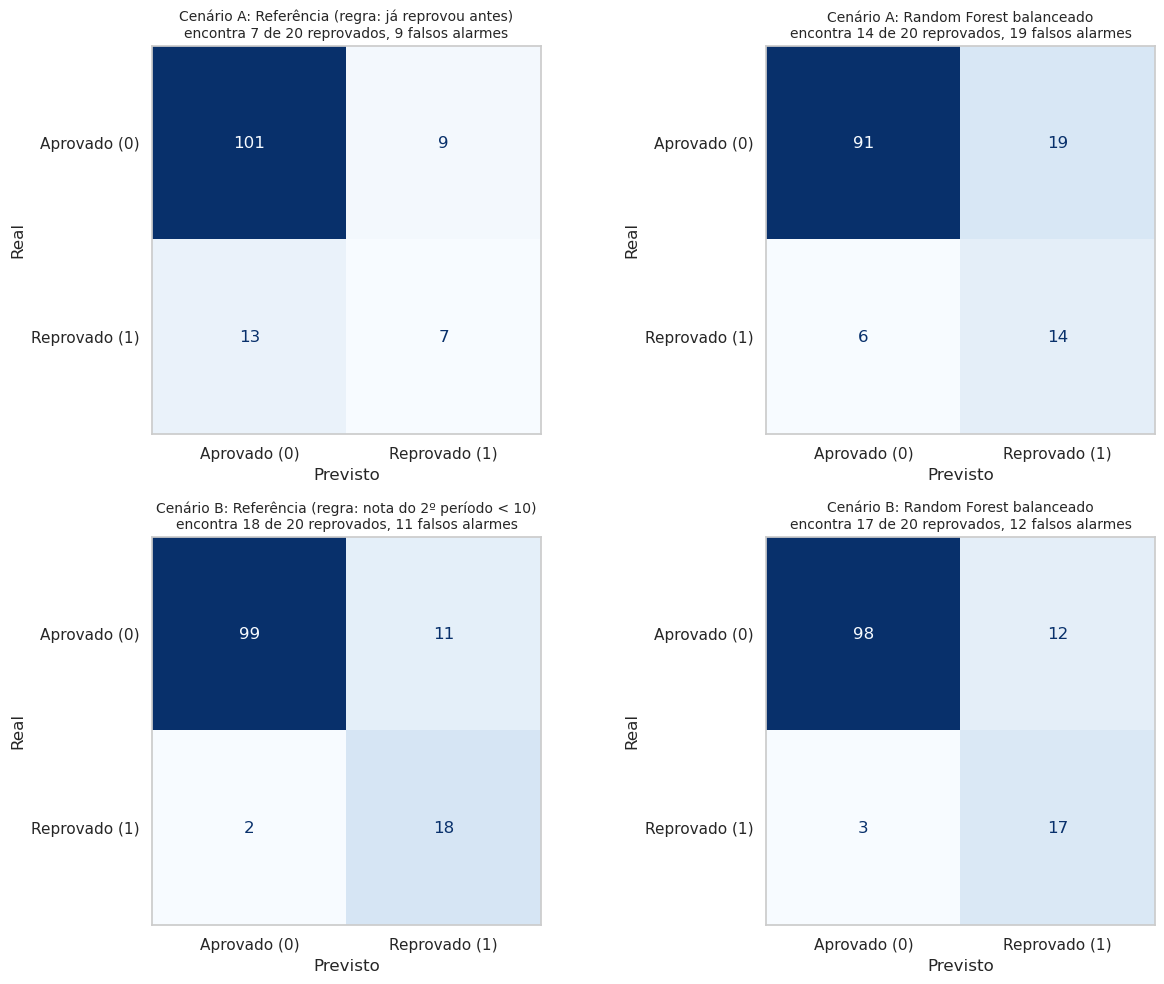

In [30]:
graficos = [("A", "Referência (regra: já reprovou antes)"), ("A", escolhido_a),
            ("B", "Referência (regra: nota do 2º período < 10)"), ("B", escolhido_b)]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (cenario, nome) in zip(axes.ravel(), graficos):
    cm = confusion_matrix(y_teste, prever(cenario, nome, teste))
    ConfusionMatrixDisplay(cm, display_labels=["Aprovado (0)", "Reprovado (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Cenário {cenario}: {nome}\nencontra {cm[1, 1]} de {cm[1].sum()} reprovados, {cm[0, 1]} falsos alarmes",
                 fontsize=10)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
    ax.grid(False)

plt.tight_layout()
plt.show()

No teste há 130 alunos, sendo 20 reprovados.

* Referência ingênua: 84,6% de acurácia, mas encontra 0 dos 20 reprovados. É o exemplo de por que a acurácia sozinha engana aqui.
* Cenário A, regra "já reprovou antes": indica 16 alunos e encontra 7 dos 20 reprovados (35%), com 9 falsos alarmes.
* Cenário A, modelo escolhido (Random Forest balanceado): indica 33 alunos e encontra 70% dos que iam reprovar (14 de 20) ainda no início do ano, com 19 falsos alarmes. A precisão é de 42%: de cada 100 alunos indicados, cerca de 42 reprovariam. A Logística balanceada encontrou 11 de 20 (21 falsos alarmes) e a sem balanceamento só 2 de 20. Como o modelo indica o dobro de alunos da regra, essa comparação ainda não é justa; ela é refeita logo abaixo.
* Cenário B: a regra "nota do 2º período < 10" encontra 18 de 20 reprovados, com 11 falsos alarmes (F1 = 0,735). O Random Forest escolhido encontra 17 de 20, com 12 falsos alarmes (F1 = 0,694). A pequena vantagem que ele teve na validação não apareceu no teste. A recomendação não vem do resultado do teste: os dois caminhos têm desempenho parecido, e nesse caso preferimos a regra, que qualquer professor entende e aplica sem modelo.

Para a escola, um falso alarme custa uma vaga de reforço para um aluno que passaria de qualquer forma; perder um reprovado significa não ajudar quem precisava. Por isso priorizamos o recall e aceitamos uma precisão menor.

## 5.2 Comparação justa entre o modelo e a regra

No Cenário A, o modelo encontrou o dobro de reprovados da regra "já reprovou antes", mas também indicou o dobro de alunos. Para entender essa diferença, primeiro separamos os reprovados do teste entre quem já tinha reprovado e quem nunca tinha reprovado.

In [31]:
previsto_regra = regra_a(teste)
previsto_modelo = modelos_a[escolhido_a].predict(teste[features_a])

reprovou = y_teste == 1
ja_reprovou = teste["Reprovacoes_Anteriores"] > 0
achou_regra = (previsto_regra == 1) & reprovou
achou_modelo = (previsto_modelo == 1) & reprovou

print("Alunos indicados para apoio: regra =", previsto_regra.sum(), "| modelo =", previsto_modelo.sum())

pd.DataFrame({
    "Reprovados no teste": [(reprovou & ja_reprovou).sum(), (reprovou & ~ja_reprovou).sum()],
    "Encontrados pela regra": [(achou_regra & ja_reprovou).sum(), (achou_regra & ~ja_reprovou).sum()],
    "Encontrados pelo modelo": [(achou_modelo & ja_reprovou).sum(), (achou_modelo & ~ja_reprovou).sum()],
}, index=["Já tinham reprovado antes", "Nunca tinham reprovado"])

Alunos indicados para apoio: regra = 16 | modelo = 33


,Reprovados no teste,Encontrados pela regra,Encontrados pelo modelo
Já tinham reprovado antes,7,7,6
Nunca tinham reprovado,13,0,8


Uma comparação justa precisa que os dois indiquem o mesmo número de alunos. O modelo dá a cada aluno uma probabilidade de reprovar; ordenamos os alunos por essa probabilidade e pegamos a mesma quantidade que a regra indica. Fazemos isso no treino, com probabilidades da validação cruzada (cada aluno é previsto por um modelo que não o viu no ajuste), e no teste. Também comparamos com uma regra de duas variáveis, "já reprovou antes ou estuda na escola MS", montada a partir das duas variáveis mais importantes do modelo (seção 6.4).

In [32]:
modelo_a = modelos_a[escolhido_a]

# probabilidade de reprovar de cada aluno
# no treino usamos a validação cruzada, para cada aluno ser previsto por um modelo que não o viu
prob_treino = cross_val_predict(modelo_a, treino[features_a], y_treino, cv=cv, method="predict_proba")[:, 1]
prob_teste = modelo_a.predict_proba(teste[features_a])[:, 1]

# se houvesse probabilidades repetidas, a escolha dos alunos no corte ficaria arbitrária
print("Probabilidades diferentes: treino", len(np.unique(prob_treino)), "de", len(prob_treino),
      "| teste", len(np.unique(prob_teste)), "de", len(prob_teste))

linhas = []
for conjunto, dados, prob in [("Treino (validação cruzada)", treino, prob_treino), ("Teste", teste, prob_teste)]:
    y = dados["Risco_Reprovacao"].to_numpy()
    regras = {
        "Já reprovou antes": (dados["Reprovacoes_Anteriores"] > 0).to_numpy(),
        "Já reprovou antes ou estuda na MS": ((dados["Reprovacoes_Anteriores"] > 0) | (dados["Escola"] == "MS")).to_numpy(),
    }
    for nome, indicados in regras.items():
        n = indicados.sum()
        mais_provaveis = np.argsort(-prob)[:n]  # os n alunos com maior probabilidade
        linhas.append([conjunto, nome, n, y[indicados].sum(), y[mais_provaveis].sum(), y.sum()])

pd.DataFrame(linhas, columns=["Conjunto", "Regra", "Alunos indicados", "Reprovados achados pela regra",
                              "Reprovados achados pelo modelo (mesmo nº)", "Total de reprovados"])

Probabilidades diferentes: treino 519 de 519 | teste 130 de 130


,Conjunto,Regra,Alunos indicados,Reprovados achados pela regra,Reprovados achados pelo modelo (mesmo nº),Total de reprovados
0,Treino (validação cruzada),Já reprovou antes,84,42,42,80
1,Treino (validação cruzada),Já reprovou antes ou estuda na MS,220,68,67,80
2,Teste,Já reprovou antes,16,7,7,20
3,Teste,Já reprovou antes ou estuda na MS,53,16,17,20


O que as duas tabelas mostram:

* A maioria dos reprovados do teste (13 de 20) nunca tinha reprovado antes. A regra não enxerga esses alunos; o modelo encontrou 8 deles, mas indicando o dobro de alunos.
* Com o mesmo número de indicados, o modelo encontra praticamente os mesmos reprovados que as regras. Contra "já reprovou antes": 7 a 7 no teste e 42 a 42 na validação. Contra "já reprovou antes ou estuda na MS": 17 contra 16 no teste e 67 contra 68 na validação.

Ou seja, o modelo não acerta mais por aluno indicado. O que ele acrescenta é ordenar todos os alunos por risco: com essa lista, a escola escolhe quantos alunos atender de acordo com as vagas, o que uma regra fixa não permite. Quase todo o sinal disponível no início do ano está em duas informações que a escola já tem, reprovações anteriores e escola. A regra de duas variáveis foi montada depois de vermos as variáveis mais importantes do modelo, então ela serve como verificação, e não como um modelo escolhido de antemão.

## 5.3 Modelo escolhido e melhor modelo em cada métrica

A tabela abaixo mostra, para cada cenário e cada métrica, qual modelo teve o melhor resultado, na validação cruzada (treino) e no teste. As referências ficam de fora, porque servem de comparação e não são candidatas.

In [33]:
linhas = []
for cenario, tabela_cv in [("A", cv_a), ("B", cv_b)]:
    # as referências ficam de fora
    modelos_cv = tabela_cv[~tabela_cv["Modelo"].str.startswith("Referência")]
    modelos_teste = teste_clf[(teste_clf["Cenário"] == cenario) & ~teste_clf["Modelo"].str.startswith("Referência")]

    for metrica in ["Recall validação (CV)", "Precisão validação (CV)", "F1 validação (CV)"]:
        melhor = modelos_cv.loc[modelos_cv[metrica].idxmax()]
        linhas.append([cenario, "Validação (treino)", metrica, melhor["Modelo"], melhor[metrica]])

    for metrica in ["Recall teste (%)", "Precisão teste (%)", "F1 teste", "Acurácia teste (%)"]:
        melhor = modelos_teste.loc[modelos_teste[metrica].idxmax()]
        linhas.append([cenario, "Teste", metrica, melhor["Modelo"], melhor[metrica]])

pd.DataFrame(linhas, columns=["Cenário", "Conjunto", "Métrica", "Melhor modelo", "Valor"]).round(3)

,Cenário,Conjunto,Métrica,Melhor modelo,Valor
0,A,Validação (treino),Recall validação (CV),Random Forest balanceado,0.738
1,A,Validação (treino),Precisão validação (CV),Logística sem balanceamento,0.564
2,A,Validação (treino),F1 validação (CV),Random Forest balanceado,0.522
3,A,Teste,Recall teste (%),Random Forest balanceado,70.000
4,A,Teste,Precisão teste (%),Random Forest balanceado,42.424
5,A,Teste,F1 teste,Random Forest balanceado,0.528
6,A,Teste,Acurácia teste (%),Logística sem balanceamento,83.077
7,B,Validação (treino),Recall validação (CV),Logística balanceada (L2),0.938
8,B,Validação (treino),Precisão validação (CV),Logística sem balanceamento,0.762
9,B,Validação (treino),F1 validação (CV),Random Forest balanceado,0.791


Modelo escolhido: Random Forest balanceado, nos dois cenários. A escolha foi feita antes de olhar o teste, pelo critério definido na Etapa 4: o maior F1 na validação cruzada (0,522 no Cenário A e 0,791 no Cenário B). Usamos o F1 porque ele exige encontrar os reprovados (recall) sem gerar alarmes demais (precisão).

Cenário A (início do ano). O Random Forest balanceado foi o melhor em quase todas as métricas: maior recall na validação (74%) e no teste (70%, 14 de 20 reprovados), maior F1 na validação (0,522) e no teste (0,528) e, no teste, também a maior precisão (42,4%). A Logística sem balanceamento teve a maior precisão na validação (56%) e a maior acurácia no teste (83,1%), mas encontrou só 2 dos 20 reprovados: gera poucos alarmes porque quase nunca aponta alguém. A acurácia é a métrica que mais engana aqui, já que a referência que diz "aprovado" para todos tem acurácia ainda maior (84,6%) e não encontra nenhum reprovado.

Cenário B (fim do 2º período). O resultado é dividido. Na validação, o Random Forest teve o maior F1 (0,791). No teste, o maior F1 foi o da Logística sem balanceamento (0,762) e o maior recall foi o da Logística balanceada (90%, 18 de 20). Nenhum modelo vence em todas as métricas, e todos ficam perto da regra "nota do 2º período < 10" (F1 de 0,735 no teste), que por isso é a recomendação para esse momento.

Em resumo, a métrica principal do projeto é o F1 da classe reprovado, apoiado pelo recall, e por esse critério o melhor modelo é o Random Forest balanceado. Como mostra a seção 5.2, porém, com o mesmo número de alunos indicados ele empata com regras simples: o ganho dele está em ordenar os alunos por risco.

---

# Etapa 6: Boas Práticas, Limitações e Conclusão

> **Enunciado da Especificação (Etapa 6):** *"6. Boas práticas, conforme a necessidade: evitar overfitting, validação adequada, regularização, tratamento de classes desbalanceadas e cuidado com vazamento de informações."*

## 6.1 Overfitting: comparação entre treino e teste

Um modelo com sobreajuste (overfitting) vai muito bem nos alunos que viu no treino e mal nos alunos novos, porque decorou detalhes em vez de aprender o padrão. Por isso comparamos o F1 no treino e no teste: quanto maior a diferença, mais o modelo decorou.

In [34]:
comparacao = teste_clf[["Cenário", "Modelo", "Recall treino (%)", "Recall teste (%)", "F1 treino", "F1 teste"]].copy()
comparacao["Diferença de F1 (treino - teste)"] = comparacao["F1 treino"] - comparacao["F1 teste"]
comparacao.round(2)

,Cenário,Modelo,Recall treino (%),Recall teste (%),F1 treino,F1 teste,Diferença de F1 (treino - teste)
0,A,Referência (classe mais comum),0.00,0.0,0.00,0.00,0.00
1,A,Referência (regra: já reprovou antes),52.50,35.0,0.51,0.39,0.12
2,A,Logística sem balanceamento,36.25,10.0,0.48,0.15,0.33
3,A,Logística balanceada (L2),70.00,55.0,0.53,0.42,0.11
4,A,Random Forest balanceado,77.50,70.0,0.55,0.53,0.02
5,B,Referência (classe mais comum),0.00,0.0,0.00,0.00,0.00
6,B,Referência (regra: nota do 2º período < 10),88.75,90.0,0.72,0.74,-0.01
7,B,Logística sem balanceamento,80.00,80.0,0.85,0.76,0.09
8,B,Logística balanceada (L2),98.75,90.0,0.78,0.71,0.08
9,B,Random Forest balanceado,100.00,85.0,1.00,0.69,0.31


* Cenário A: o Random Forest escolhido quase não perde desempenho do treino para o teste (F1 de 0,55 para 0,53), porque a validação escolheu árvores rasas (profundidade 2, com pelo menos 10 alunos por folha). A Logística balanceada cai de 0,53 para 0,42, e a sem balanceamento de 0,48 para 0,15.
* Cenário B: o Random Forest escolhido tem F1 de 1,00 no treino e 0,69 no teste, a maior queda da tabela (0,31). Com as notas parciais, a validação preferiu árvores profundas (profundidade 12, com folhas de 1 aluno), que decoram o treino. Esse sobreajuste ajuda a explicar por que ele não superou a regra no teste. As duas Logísticas perdem bem menos (0,08 e 0,09).
* As regras não aprendem nada dos dados. Mesmo assim, o F1 delas muda entre treino e teste (de 0,51 para 0,39 no Cenário A), o que mostra quanto o próprio teste, com só 20 reprovados, faz os números variarem.

A validação cruzada com 5 partes protegeu a escolha dos hiperparâmetros, mas não eliminou o sobreajuste do Random Forest no Cenário B. Por isso foi importante comparar os modelos também com uma regra simples, e não só com a referência ingênua.

## 6.2 Vazamento de informação

O vazamento é perigoso porque, se o modelo usar uma informação que contém a resposta, ou que ainda não existiria no momento da previsão, ele parece ótimo na avaliação e falha quando a escola for usar de verdade. Conferimos no código que nenhuma variável derivada da resposta entrou no modelo e que o Cenário A não usa nada que só existe depois do início do ano.

In [35]:
todas_as_features = features_a + features_b

print("Alguma variável de resposta nas entradas?", any(c in respostas for c in todas_as_features))
print("Notas parciais no Cenário A?", any(c in notas_parciais for c in features_a))
print("Faltas em algum cenário?", "Numero_de_Faltas" in todas_as_features)
print("Alunos em comum entre treino e teste:", len(set(treino.index) & set(teste.index)))

Alguma variável de resposta nas entradas? False
Notas parciais no Cenário A? False
Faltas em algum cenário? False
Alunos em comum entre treino e teste: 0


Resumo do que fizemos para evitar vazamento:

* Divisão antes de qualquer ajuste: o `train_test_split` foi feito na Etapa 3, antes de padronizar ou codificar. O `StandardScaler` e o `OneHotEncoder` estão dentro do `Pipeline`, então aprendem só com o treino (e, na validação cruzada, só com as partes de treino de cada rodada).
* Teste usado uma vez: hiperparâmetros e modelo escolhido saíram da validação cruzada no treino. O teste só foi usado na Etapa 5.
* Variáveis que contêm a resposta: `Situacao_Final` e `Risco_Reprovacao` são calculadas a partir da `Nota_Final` e ficaram fora das entradas.
* Disponibilidade no tempo: separamos os cenários A e B e deixamos `Numero_de_Faltas` fora dos dois, porque o total do ano só é conhecido no fim do ano letivo. A diferença de desempenho entre eles (Etapa 5) mostra o tamanho do efeito das notas parciais. Se tivéssemos usado as notas no "alerta do início do ano", o modelo pareceria ótimo, mas seria impossível usá-lo na prática.

## 6.3 Regularização

A regularização é importante neste problema: o treino tem só 80 reprovados, e algumas entradas são correlacionadas entre si (escolaridade da mãe e do pai, os dois tipos de consumo de álcool, seção 2.15). Nessa situação, um modelo sem controle tende a dar pesos grandes a detalhes do treino que não se repetem em alunos novos. A regularização encolhe os coeficientes e deixa o modelo mais simples.

Na Regressão Logística, o parâmetro `C` controla a regularização: quanto menor o `C`, mais os coeficientes são encolhidos. Para mostrar o efeito, treinamos a Logística balanceada do Cenário A com vários valores de `C` e comparamos o F1 no treino e na validação cruzada (só com os dados de treino).

In [36]:
linhas = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    pipe = criar_pipeline(LogisticRegression(C=C, class_weight="balanced", max_iter=5000), features_a)
    r = cross_validate(pipe, treino[features_a], y_treino, cv=cv, scoring=metricas["f1"], return_train_score=True)

    pipe.fit(treino[features_a], y_treino)
    soma_coef = np.abs(pipe.named_steps["modelo"].coef_).sum()

    f1_treino = r["train_score"].mean()
    f1_validacao = r["test_score"].mean()
    linhas.append([C, f1_treino, f1_validacao, f1_treino - f1_validacao, soma_coef])

pd.DataFrame(linhas, columns=["C", "F1 treino (CV)", "F1 validação (CV)",
                              "Diferença (treino - validação)", "Soma |coeficientes|"]).round(3)

,C,F1 treino (CV),F1 validação (CV),Diferença (treino - validação),Soma |coeficientes|
0,0.001,0.519,0.497,0.022,0.659
1,0.010,0.554,0.478,0.077,2.673
2,0.100,0.587,0.461,0.127,7.367
3,1.000,0.592,0.432,0.160,13.386
4,10.000,0.605,0.412,0.192,15.707
5,100.000,0.605,0.412,0.193,16.029


* Quanto menor o `C`, mais forte a regularização e menores os coeficientes: a soma dos coeficientes (em módulo) vai de 16,03 com `C=100` para 0,66 com `C=0,001`.
* Com regularização fraca (`C` de 1 a 100), o modelo se ajusta mais ao treino (F1 de cerca de 0,60) e piora na validação (0,41 a 0,43); a diferença entre treino e validação chega a 0,19. Com `C=0,001`, a diferença cai para 0,02 e o F1 de validação é o maior da tabela (0,497).
* Esse foi o valor escolhido pelo `GridSearchCV` na Etapa 4. Com apenas 80 reprovados no treino e 29 variáveis, um modelo com coeficientes pequenos generaliza melhor do que um que tenta aproveitar cada detalhe dos dados.
* No Random Forest, a regularização é feita limitando a profundidade das árvores e o número mínimo de alunos por folha. No Cenário A, a validação escolheu árvores de profundidade 2 com pelo menos 10 alunos por folha.

## 6.4 Classes desbalanceadas e variáveis que mais pesam no alerta do início do ano

O desbalanceamento precisava de tratamento: com 85% de aprovados, um modelo sem ajuste aprende que dizer "aprovado" quase sempre acerta, e quase não aponta reprovados. Foi o que aconteceu com a Logística sem balanceamento, que encontrou só 2 dos 20 reprovados do teste.

Escolhemos `class_weight="balanced"` em vez de SMOTE ou outra reamostragem porque o ajuste de pesos dá mais importância aos reprovados durante o treino sem criar alunos artificiais, é simples e já vem nos modelos do scikit-learn. Como ele já resolveu o problema, não foi preciso nada mais complexo.

Também queríamos saber em que o modelo se baseia e se isso faz sentido para a escola. Para isso, primeiro medimos a importância das variáveis no modelo escolhido para o Cenário A (Random Forest). A importância por permutação embaralha uma variável de cada vez e mede quanto o desempenho do modelo cai (AUC, nos dados de treino). Quanto maior a queda, mais o modelo depende daquela variável. Usamos o treino para não reutilizar o teste.

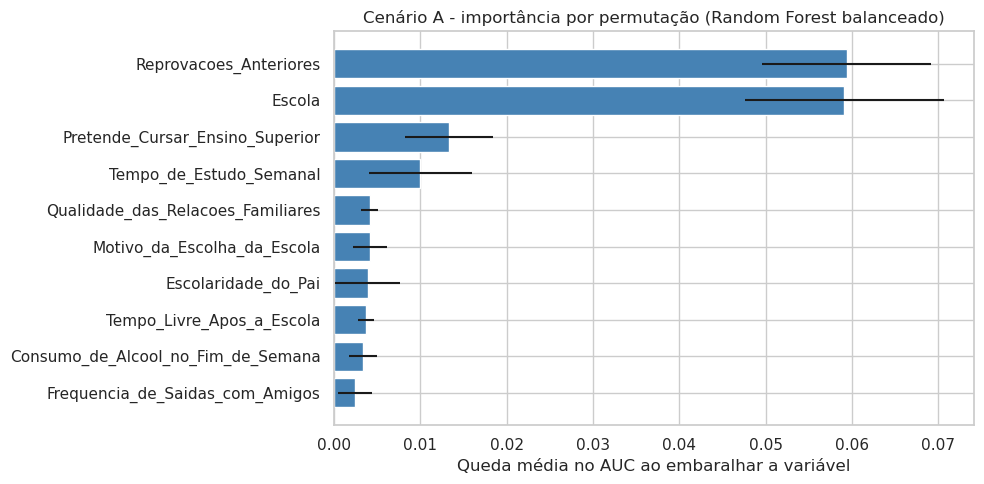

In [37]:
modelo_a = modelos_a[escolhido_a]
perm = permutation_importance(modelo_a, treino[features_a], y_treino, scoring="roc_auc",
                              n_repeats=20, random_state=SEMENTE)

importancia = pd.DataFrame({"Variável": features_a,
                            "Queda no AUC": perm.importances_mean,
                            "Desvio": perm.importances_std})
importancia = importancia.sort_values("Queda no AUC").tail(10)  # as 10 mais importantes

plt.figure(figsize=(10, 5))
plt.barh(importancia["Variável"], importancia["Queda no AUC"], xerr=importancia["Desvio"], color="steelblue")
plt.title("Cenário A - importância por permutação (" + escolhido_a + ")")
plt.xlabel("Queda média no AUC ao embaralhar a variável")
plt.tight_layout()
plt.show()

A importância por permutação não diz se a variável aumenta ou reduz o risco. Para ver a direção, usamos os coeficientes da Logística balanceada, que teve desempenho próximo ao do Random Forest na validação.

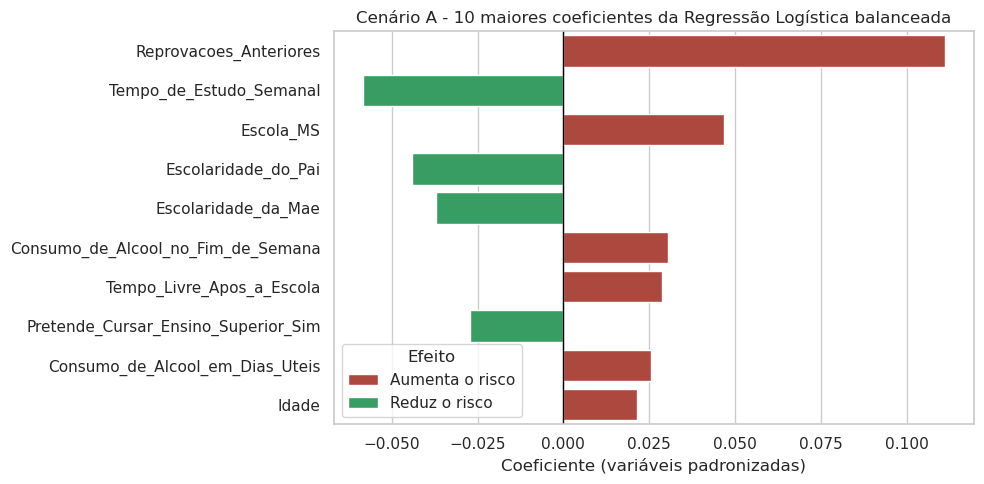

In [38]:
logistica = modelos_a["Logística balanceada (L2)"]

nomes = logistica.named_steps["prep"].get_feature_names_out()
nomes = [n.replace("num__", "").replace("cat__", "") for n in nomes]

coeficientes = pd.DataFrame({"Variável": nomes, "Coeficiente": logistica.named_steps["modelo"].coef_[0]})
coeficientes["Efeito"] = np.where(coeficientes["Coeficiente"] > 0, "Aumenta o risco", "Reduz o risco")
coeficientes["Tamanho"] = coeficientes["Coeficiente"].abs()
top = coeficientes.sort_values("Tamanho", ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top, x="Coeficiente", y="Variável", hue="Efeito",
            palette={"Aumenta o risco": "#c0392b", "Reduz o risco": "#27ae60"}, dodge=False)
plt.axvline(0, color="black", linewidth=1)
plt.title("Cenário A - 10 maiores coeficientes da Regressão Logística balanceada")
plt.xlabel("Coeficiente (variáveis padronizadas)")
plt.ylabel("")
plt.tight_layout()
plt.show()

Efeito do balanceamento: no teste do Cenário A, a Logística sem balanceamento encontrou 2 dos 20 reprovados; com `class_weight="balanced"` passou para 11 de 20, e o Random Forest balanceado chegou a 14 de 20. No Cenário B, o recall da Logística foi de 80% para 90%. O custo é uma precisão menor (mais falsos alarmes), aceitável para uma ação de apoio.

Variáveis mais importantes: as duas medidas apontam para os mesmos fatores. No Random Forest, escola e reprovações anteriores são, de longe, as variáveis de que o modelo mais depende (queda de cerca de 0,06 no AUC cada uma), seguidas de querer cursar o ensino superior e do tempo de estudo. Na Logística, que mostra a direção do efeito, o que mais aumenta o risco é o número de reprovações anteriores e estudar na escola MS; o que mais reduz é o tempo de estudo semanal, a escolaridade do pai e da mãe e querer cursar o ensino superior. Com peso menor, o consumo de álcool, o tempo livre e a idade também aparecem aumentando o risco. Os coeficientes são pequenos por causa da regularização forte, mas podem ser comparados entre si porque as variáveis foram padronizadas.

Esses coeficientes mostram associação, não causa. Estudar na escola MS não causa reprovação; a escola provavelmente reúne outros fatores que a base não mede.

## 6.5 Limitações

* Generalização: são 649 alunos de duas escolas portuguesas, numa única disciplina (Língua Portuguesa) e num único ano de coleta. Para usar em outras escolas, inclusive brasileiras, o modelo teria de ser treinado de novo com dados locais.
* Tamanho do teste: o teste tem só 20 reprovados. Um aluno a mais ou a menos muda o recall em 5 pontos percentuais, então os números devem ser lidos como aproximados. Isso ajuda a explicar por que a validação e o teste discordaram no Cenário B.
* Faltas fora dos modelos: a base só traz o total de faltas do ano, que não existe no início do ano nem está completo no fim do 2º período. Por isso deixamos as faltas de fora, mesmo sabendo que a frequência é um sinal útil. Com as faltas registradas por período, o modelo poderia melhorar.
* Notas zero: os 15 alunos com nota final zero e nenhuma falta parecem ser abandonos ou ausência na avaliação, mas a base não confirma. Eles entram no alvo como reprovados.
* Dados de questionário: tempo de estudo, consumo de álcool, saúde e relação familiar são respostas dos próprios alunos e podem ter viés (por exemplo, subestimar o consumo de álcool).
* Desempenho do Cenário A: sem notas, menos da metade dos alunos apontados (42%) de fato reprovaria e, com o mesmo número de indicados, ele não supera regras simples. Ele serve para priorizar quem recebe atenção, não para afirmar que um aluno vai reprovar.
* Limiar de decisão: as tabelas da Etapa 5 usam o corte padrão de 50% de probabilidade. A seção 5.2 mostra que, ordenando os alunos por probabilidade, a escola pode ajustar o tamanho da lista às vagas; não definimos um corte ideal porque isso depende do número de vagas, que a base não informa.
* Uso responsável: variáveis como escola, sexo e situação familiar não devem servir para rotular alunos. A saída do modelo deve virar oferta de apoio, nunca punição ou exclusão.

## 6.6 Conclusão

O projeto apoia uma decisão da coordenação pedagógica: quais alunos devem receber os recursos de apoio (reforço, tutoria, acompanhamento com a família), que são limitados. As conclusões abaixo se apoiam nos resultados das Etapas 4 a 6.

Modelo escolhido e por quê. O Random Forest balanceado foi escolhido nos dois cenários porque teve o maior F1 na validação cruzada (0,522 no início do ano e 0,791 no fim do 2º período), critério definido antes de olhar o teste. No início do ano, o teste confirmou a escolha: entre os modelos, ele teve o maior recall (70%), a maior precisão (42,4%) e o maior F1 (0,528) (seção 5.3). Uma explicação provável para a vantagem sobre a Logística é que as árvores combinam variáveis, como escola e reprovações anteriores, sem que seja preciso indicar essas combinações.

Métrica principal e por quê. A métrica principal foi o F1 da classe reprovado, acompanhado do recall. Com 15% de reprovados, a acurácia engana: dizer "aprovado" para todos dá 84,6% de acurácia e não encontra nenhum reprovado. O recall mede o que mais importa para a escola, que é não deixar de ajudar quem vai reprovar, e o F1 impede que isso seja obtido simplesmente indicando todos os alunos.

Quem precisa de apoio. No início do ano, sem nenhuma nota, o Random Forest indicou 33 alunos e encontrou 14 dos 20 que iam reprovar no teste. De cada 100 indicados, cerca de 42 reprovariam, contra cerca de 15 se a escola escolhesse alunos ao acaso. A regra "quem já reprovou antes" indica 16 alunos e encontra 7. A comparação justa, com o mesmo número de indicados, mostra que o modelo e a regra encontram a mesma quantidade de reprovados (7 a 7 no teste e 42 a 42 na validação), e que a regra "já reprovou antes ou estuda na MS" chega a um resultado parecido com o do modelo (seção 5.2). O modelo, portanto, não acerta mais por aluno indicado. O que ele acrescenta é uma lista ordenada por risco, com a qual a escola escolhe quantos alunos atender conforme as vagas, e que, quando é mais longa, alcança alunos que nunca tinham reprovado (8 dos 13 desse grupo no teste), que a regra do histórico não enxerga.

Quando agir. No começo do ano, a lista sai do histórico do aluno, pela ordem do modelo ou pela regra. Depois do 2º período, a regra "nota do 2º período abaixo de 10" encontrou 18 dos 20 reprovados no teste. Na validação o Random Forest teve F1 um pouco maior (0,79 contra 0,73), mas mostrou sobreajuste (F1 de 1,00 no treino e 0,69 no teste) e a vantagem não apareceu no teste. Como os dois caminhos têm desempenho parecido, recomendamos a regra, que é mais simples e dispensa modelo. A lista do começo do ano deve ser revisada com ela.

Onde concentrar esforços. As duas medidas de importância da seção 6.4 apontam os mesmos fatores: reprovações anteriores e escola pesam mais, seguidas de querer cursar o ensino superior e do tempo de estudo. A análise exploratória mostra o mesmo. A escola MS reprova 30,09% dos alunos, contra 7,57% da GP, e a diferença continua grande mesmo sem os 14 alunos da MS com nota final zero (25,47% contra 7,35%). Quem já reprovou antes tem de 45,71% a 64,29% de reprovação, contra 9,29% de quem nunca reprovou, lembrando que os grupos com 2 e com 3 ou mais reprovações têm só 16 e 14 alunos. São diferenças que a coordenação deveria investigar.

A confiança nesses resultados vem das boas práticas aplicadas. Os números da Etapa 5 vêm de um teste que não participou de nenhuma escolha. O pré-processamento foi ajustado só no treino, dentro do `Pipeline`; nenhuma variável usada estaria indisponível no momento da previsão (as faltas do ano ficaram de fora); o desbalanceamento foi tratado com `class_weight="balanced"`; e a validação cruzada e a regularização controlaram o sobreajuste no Cenário A (F1 de 0,55 no treino e 0,53 no teste). No Cenário B, onde o Random Forest sobreajustou, a comparação com a regra simples evitou recomendar um modelo que não se sustenta.

Limites. O resultado vem de 649 alunos de duas escolas portuguesas e de um teste com só 20 reprovados, então os números são aproximados, e o modelo precisaria ser treinado de novo para outra escola. As relações encontradas são associações, não causas: não dá para afirmar que trocar de escola ou mudar a rotina aumentaria a nota. O modelo deve ser usado para priorizar quem recebe atenção, nunca para rotular ou punir.

No fim, o resultado mais útil do projeto foi mostrar, com uma avaliação cuidadosa, que nesta base o risco de reprovação se concentra em poucas informações que a escola já tem. O modelo ajuda a ordenar os alunos por risco no começo do ano, mas não supera regras simples quando os dois indicam o mesmo número de alunos; depois do 2º período, a nota parcial basta.